# Customer-experience risk modeling

Two complementary models support customer-experience monitoring. The primary model ranks individual orders at placement using the probability of an eventual low review. The secondary model ranks historically active sellers using the probability of at least one observed low-review event among the next month's orders.

The models have different prediction units, targets, eligibility rules, and evaluation periods. Their AP and lift values are interpreted within each task, not compared as competing models.

In [88]:
import warnings
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    average_precision_score,
    classification_report,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier


In [89]:
# Resolve data files using the GitHub repository folder structure.
from pathlib import Path

def resolve_data_file(filename, data_type="raw"):
    data_path = Path("..") / "01_data" / data_type / filename
    if not data_path.is_file():
        raise FileNotFoundError(
            f"Could not find {filename} at {data_path}. "
            "Run this notebook from the repository's 02_notebooks folder."
        )
    return data_path


## Part I — Order-level risk at placement

### Objective

Delivery performance is an important indicator of customer experience, but
fulfillment outcomes are not available when an order is placed. Identifying
potentially dissatisfied customers earlier could help Olist prioritize
transactions for proactive monitoring and support.

This analysis develops a classification model to predict the risk of an
eventual low customer review using information available at order placement.
The target, `low_review_2`, identifies orders receiving a final observed
review of 1–2 stars, compared with orders receiving 3–5 stars.

The primary objective is to **rank orders by relative risk**, rather than
automatically classify or intervene on every potentially dissatisfied
customer. Model performance is therefore evaluated using average precision
and risk concentration among the highest-ranked orders, with a hypothetical
top-decile monitoring capacity.

The analysis compares multiple classification approaches, evaluates their
ability to generalize to later orders, and examines whether predictive
signal remains among orders that ultimately meet their delivery promise.

## Order-level Modeling Population

The item-level baseline is aggregated to one observation per order. Aggregated
features describe basket value and complexity, product characteristics, seller
geography, and product-category composition. An order is considered cross-state
if at least one seller is located outside the customer's state. Missing aggregate product weights and zero-valued weight totals are treated as missing for subsequent imputation.

The supervised population consists of orders with an observed customer review.
The binary target, `low_review_2`, identifies orders whose latest answered
review received 1–2 stars, with 3–5 stars representing the comparison group.

Review-answer timestamps are retained to establish when outcomes became
observable for chronological training, but are excluded from the predictors.

In [90]:
# Load the item baseline and raw review timestamps.
olist_df = pd.read_csv(
    str(resolve_data_file("olist_order_item_baseline.csv", "preprocessed")),
    parse_dates=[
        "order_purchase_timestamp",
        "order_estimated_delivery_date",
        "order_delivered_customer_date",
    ],
)

reviews = pd.read_csv(
    str(resolve_data_file("olist_order_reviews_dataset.csv", "raw")),
    parse_dates=["review_answer_timestamp"],
)

In [91]:
# Collapse item rows to one row per order.
order_df = (
    olist_df.groupby("order_id")
    .agg(
        merchandise_value=("price", "sum"),
        freight_value=("freight_value", "sum"),
        item_count=("order_item_id", "size"),
        unique_product_count=("product_id", "nunique"),
        unique_seller_count=("seller_id", "nunique"),
        total_product_weight_g=(
            "product_weight_g", lambda values: values.sum(min_count=1)
        ),
        avg_product_photos=("product_photos_qty", "mean"),
        avg_product_name_length=("product_name_lenght", "mean"),
        avg_product_description_length=("product_description_lenght", "mean"),
        unique_category_count=(
            "product_category_name",
            lambda values: values.fillna("unknown").nunique(),
        ),
        customer_unique_id=("customer_unique_id", "first"),
        customer_state=("customer_state", "first"),
        order_purchase_timestamp=("order_purchase_timestamp", "first"),
        order_estimated_delivery_date=("order_estimated_delivery_date", "first"),
        last_review_score=("last_review_score", "first"),
    )
    .reset_index()
)
# Treat zero total weights as missing for later imputation.
order_df["total_product_weight_g"] = order_df["total_product_weight_g"].replace(
    0, np.nan
)
order_df["freight_share"] = order_df["freight_value"] / (
    order_df["merchandise_value"] + order_df["freight_value"]
)
order_df["promised_delivery_days"] = (
    order_df["order_estimated_delivery_date"]
    - order_df["order_purchase_timestamp"]
).dt.total_seconds() / 86400

# Represent category presence, not the number of matching items.
categories = pd.crosstab(
    olist_df["order_id"], olist_df["product_category_name"].fillna("unknown")
)
categories = (categories > 0).astype(int).add_prefix("category_")

# Flag any seller outside the customer state.
cross_state = (
    olist_df["seller_state"].ne(olist_df["customer_state"])
    .where(olist_df["seller_state"].notna() & olist_df["customer_state"].notna())
    .groupby(olist_df["order_id"]).max().rename("any_cross_state")
)

# Track when the selected review outcome became observable.
latest_reviews = (
    reviews.sort_values(["order_id", "review_answer_timestamp"])
    .groupby("order_id").tail(1)
    .set_index("order_id")["review_answer_timestamp"]
    .rename("latest_review_answer_timestamp")
)
order_df = (
    order_df.join(categories, on="order_id")
    .join(cross_state, on="order_id")
    .join(latest_reviews, on="order_id")
    .dropna(subset=["last_review_score"])  # Unreviewed outcomes are unknown.
    .reset_index(drop=True)
)
order_df["low_review_2"] = order_df["last_review_score"].le(2).astype(int)
order_df["purchase_month"] = order_df["order_purchase_timestamp"].dt.month
order_df["purchase_day_of_week"] = order_df["order_purchase_timestamp"].dt.dayofweek

# Define the supervised target and summarize the modeling population.
print(f"Orders: {len(order_df):,}")
print(f"Low reviews: {order_df['low_review_2'].sum():,}")
print(f"Low-review rate: {order_df['low_review_2'].mean():.2%}")

Orders: 97,917
Low reviews: 13,893
Low-review rate: 14.19%


## Placement-time Predictors

The model uses 90 predictors representing information assumed available at order
placement. These include order value and basket complexity, product listing
characteristics, customer geography, purchase timing, and product-category
composition. Post-purchase outcomes and other unavailable information are
excluded to prevent data leakage.

Predictors are grouped according to their preprocessing requirements: numeric,
categorical, and binary. Product-category indicators represent category presence
within an order rather than the number of items in each category.

In [92]:
numeric_features = [
    "merchandise_value",
    "freight_value",
    "item_count",
    "unique_product_count",
    "unique_seller_count",
    "total_product_weight_g",
    "avg_product_photos",
    "avg_product_name_length",
    "avg_product_description_length",
    "unique_category_count",
    "freight_share",
    "promised_delivery_days",
]

categorical_features = [
    "customer_state",
    "purchase_month",
    "purchase_day_of_week",
]

# Binary category-presence indicators
product_category_features = [
    col for col in order_df.columns
    if col.startswith("category_")
]

binary_features = ["any_cross_state", *product_category_features]

feature_cols = numeric_features + categorical_features + binary_features

print(f"Predictors: {len(feature_cols)}")

Predictors: 90


## Evaluation Methodology

Two evaluation strategies assess the model's ability to identify orders at
risk of receiving a low customer review.

**Randomized evaluation:** A stratified 80/20 train/test split (`random_state=1`)
provides a benchmark for predicting unseen orders drawn from the historical
population. Hyperparameters are selected through cross-validation using
training data only.

**Chronological evaluation:** A time-based split assesses how well the model
generalizes to later orders. Training includes purchases before May 1, 2018,
whose latest review outcomes were observable before that date. Testing includes
orders placed afterward, with at least 60 days of potential review follow-up
before the dataset's final observed review.

The 60-day follow-up window accommodates 99.50% of valid historical review
delays without redefining the target. Both evaluations exclude orders without
observed reviews, so performance is conditional on review availability.

Model performance is assessed using average precision, ROC-AUC, and
top-decile risk concentration. The top 10% represents a hypothetical monitoring
capacity rather than an optimized intervention threshold.

### Review Follow-up Coverage

The calculation below supports the 60-day potential-follow-up allowance. Coverage is measured among reviewed orders with observed, nonnegative purchase-to-latest-answer intervals; negative and missing intervals are excluded from this calculation only. It measures when observed outcomes arrived, not the proportion of all orders that receive a review or a guarantee that every eventual review has arrived. The target and modeling population remain unchanged.


In [ ]:
# Measure follow-up among observed order-level reviews, not review completeness.
review_delay_days = (
    order_df["latest_review_answer_timestamp"]
    - order_df["order_purchase_timestamp"]
).dt.total_seconds() / 86400
valid_review_delay = review_delay_days.loc[review_delay_days.ge(0)]
review_followup_summary = pd.DataFrame({
    "Valid reviewed orders": [len(valid_review_delay)],
    "Latest answer within 60 days (%)": [100 * valid_review_delay.le(60).mean()],
    "Negative intervals excluded": [int(review_delay_days.lt(0).sum())],
    "Missing intervals excluded": [int(review_delay_days.isna().sum())],
})
display(review_followup_summary.round(2))


Valid reviewed orders,Latest answer within 60 days (%),Negative intervals excluded,Missing intervals excluded
97912,99.5,5,0


In [93]:
# Randomized evaluation: stratified 80/20 split.
random_train, random_test = train_test_split(
    order_df,
    test_size=0.20,
    random_state=1,
    stratify=order_df["low_review_2"],
)

# Chronological evaluation: training labels must be observable before the cutoff.
boundary = pd.Timestamp("2018-05-01")
review_end = reviews["review_answer_timestamp"].max()
test_end = review_end - pd.Timedelta(days=60)

chronological_train = order_df.loc[
    (order_df["order_purchase_timestamp"] < boundary)
    & (order_df["latest_review_answer_timestamp"] < boundary)
]

# Allow at least 60 days of potential review follow-up for test orders.
chronological_test = order_df.loc[
    order_df["order_purchase_timestamp"].between(boundary, test_end)
]

evaluation_sets = {
    "Random": (random_train, random_test),
    "Chronological": (chronological_train, chronological_test),
}

# Summarize split proportions and low-review prevalence.
evaluation_summary = pd.DataFrame(
    [
        {
            "Evaluation": name,
            "Train orders": len(train),
            "Train (%)": len(train) / (len(train) + len(test)),
            "Train prevalence": train["low_review_2"].mean(),
            "Test orders": len(test),
            "Test (%)": len(test) / (len(train) + len(test)),
            "Test prevalence": test["low_review_2"].mean(),
        }
        for name, (train, test) in evaluation_sets.items()
    ]
).set_index("Evaluation")

display(
    evaluation_summary.style.format(
        {
            "Train orders": "{:,.0f}",
            "Train (%)": "{:.1%}",
            "Train prevalence": "{:.2%}",
            "Test orders": "{:,.0f}",
            "Test (%)": "{:.1%}",
            "Test prevalence": "{:.2%}",
        }
    )
)

,Train orders,Train (%),Train prevalence,Test orders,Test (%),Test prevalence
Evaluation,,,,,,
Random,"78,333",80.0%,14.19%,"19,584",20.0%,14.19%
Chronological,"68,890",72.9%,15.28%,"25,608",27.1%,10.93%


The randomized evaluation preserves an 80/20 split and approximately equal class prevalence, while the chronological evaluation uses a historical cutoff, resulting in different split proportions and lower low-review prevalence in the later test period.

## Model Training

### Logistic Regression

Logistic regression provides an interpretable linear benchmark for predicting
low-review risk. Numeric predictors are median-imputed and standardized,
categorical predictors are one-hot encoded, and existing binary indicators
are retained without transformation.

Preprocessing is incorporated into the modeling pipeline so that imputation,
scaling, and encoding are fitted independently within each cross-validation
training fold, preventing information leakage. Regularization strength and
class weighting are selected using five-fold stratified cross-validation,
with average precision as the optimization metric.

The initial tree and ensemble searches selected boundary values. A modest expanded search checks neighboring settings using the same training folds and AP metric. The predictor specification and evaluation sets remain fixed. Holdouts have already been inspected, so subsequent results are comparative validation rather than a fresh final test.

The expanded grids are fixed as the final modest search budget. Some selected values remain at a boundary; these are the best tested configurations, not established global optima. Small CV differences do not establish a meaningful performance advantage.

In [94]:
# Fit imputation, scaling, and encoding within each training fold.
numeric_pipeline = Pipeline(
    [
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]
)

preprocessor = ColumnTransformer(
    [
        ("numeric", numeric_pipeline, numeric_features),
        (
            "categorical",
            OneHotEncoder(drop="first", handle_unknown="ignore"),
            categorical_features,
        ),
        ("binary", "passthrough", binary_features),
    ]
)

pipeline = Pipeline(
    [
        ("preprocessor", preprocessor),
        ("model", LogisticRegression(max_iter=1000)),
    ]
)

In [95]:
# Select hyperparameters using training-only cross-validation.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=1)

param_grid = {
    "model__C": [0.001, 0.01, 0.1],
    "model__class_weight": [None, "balanced"],
}

logistic_search = GridSearchCV(
    pipeline,
    param_grid,
    scoring="average_precision",
    cv=cv,
    n_jobs=2,
)

logistic_search.fit(random_train[feature_cols], random_train["low_review_2"])

cv_results = (
    pd.DataFrame(logistic_search.cv_results_)[
        [
            "param_model__C",
            "param_model__class_weight",
            "mean_test_score",
            "std_test_score",
            "rank_test_score",
        ]
    ]
    .rename(
        columns={
            "param_model__C": "C",
            "param_model__class_weight": "class_weight",
            "mean_test_score": "Mean CV AP",
            "std_test_score": "CV SD",
            "rank_test_score": "Rank",
        }
    )
    .sort_values("Rank")
)

display(cv_results.round(4))
print("Selected parameters:", logistic_search.best_params_)
print(f"Best mean CV AP: {logistic_search.best_score_:.4f}")

,C,class_weight,Mean CV AP,CV SD,Rank
2,0.010,NaN,0.251,0.007,1
4,0.100,NaN,0.250,0.006,2
3,0.010,balanced,0.250,0.007,3
5,0.100,balanced,0.249,0.006,4
1,0.001,balanced,0.247,0.006,5
0,0.001,NaN,0.246,0.006,6


Selected parameters: {'model__C': 0.01, 'model__class_weight': None}
Best mean CV AP: 0.2507


### Decision Tree

A decision tree provides a nonlinear alternative to logistic regression,
capturing interactions between predictors without requiring explicit
interaction terms.

Hyperparameters are selected using the same five-fold stratified
cross-validation and average precision metric. Maximum tree depth and
minimum leaf size are constrained to reduce overfitting. Numeric predictors
are median-imputed but do not require standardization.

Selected: depth 20, minimum leaf size 250, no class weighting (mean CV AP 0.2361). Depth remains at the search ceiling, while leaf size is bracketed by smaller and larger values.

In [96]:
# Reuse preprocessing without numeric scaling.
tree_preprocessor = clone(preprocessor).set_params(
    numeric=SimpleImputer(strategy="median")
)

tree_pipeline = Pipeline(
    [
        ("preprocessor", tree_preprocessor),
        ("model", DecisionTreeClassifier(random_state=1)),
    ]
)

tree_param_grid = {
    "model__max_depth": [5, 10, 20],
    "model__min_samples_leaf": [100, 250, 500],
    "model__class_weight": [None, "balanced"],
}

tree_search = GridSearchCV(
    tree_pipeline,
    tree_param_grid,
    scoring="average_precision",
    cv=cv,
    n_jobs=-1,
)

tree_search.fit(random_train[feature_cols], random_train["low_review_2"])

tree_cv_results = (
    pd.DataFrame(tree_search.cv_results_)[
        [
            "param_model__max_depth",
            "param_model__min_samples_leaf",
            "param_model__class_weight",
            "mean_test_score",
            "std_test_score",
            "rank_test_score",
        ]
    ]
    .rename(
        columns={
            "param_model__max_depth": "max_depth",
            "param_model__min_samples_leaf": "min_samples_leaf",
            "param_model__class_weight": "class_weight",
            "mean_test_score": "Mean CV AP",
            "std_test_score": "CV SD",
            "rank_test_score": "Rank",
        }
    )
    .sort_values("Rank")
)

display(tree_cv_results.head().round(4))
print("Selected parameters:", tree_search.best_params_)
print(f"Best mean CV AP: {tree_search.best_score_:.4f}")

,max_depth,min_samples_leaf,class_weight,Mean CV AP,CV SD,Rank
7,20,250,NaN,0.236,0.008,1
16,20,250,balanced,0.236,0.007,2
8,20,500,NaN,0.234,0.009,3
17,20,500,balanced,0.234,0.007,4
13,10,250,balanced,0.232,0.007,5


Selected parameters: {'model__class_weight': None, 'model__max_depth': 20, 'model__min_samples_leaf': 250}
Best mean CV AP: 0.2361


### Random Forest

Random forest extends the decision tree approach by combining predictions
from multiple trees, reducing the variance associated with individual trees.

The model uses the same preprocessing and five-fold stratified cross-validation
as the decision tree. Hyperparameters controlling tree depth, minimum leaf
size, and class weighting are selected using average precision.

Selected: depth 25, minimum leaf size 5, balanced class weights (mean CV AP 0.2676). Depth remains at the search ceiling. Leading configurations have similar CV AP, so the selection does not establish a meaningful advantage over nearby settings.

In [97]:
# Compare forest configurations using the same CV folds.
forest_pipeline = Pipeline(
    [
        ("preprocessor", clone(tree_preprocessor)),
        (
            "model",
            RandomForestClassifier(
                n_estimators=100,
                max_features="sqrt",
                random_state=1,
                n_jobs=1,
            ),
        ),
    ]
)

forest_param_grid = {
    "model__max_depth": [15, 20, 25],
    "model__min_samples_leaf": [1, 5, 10],
    "model__class_weight": [None, "balanced"],
}

forest_search = GridSearchCV(
    forest_pipeline,
    forest_param_grid,
    scoring="average_precision",
    cv=cv,
    n_jobs=-1,
)

forest_search.fit(random_train[feature_cols], random_train["low_review_2"])

forest_cv_results = (
    pd.DataFrame(forest_search.cv_results_)[
        [
            "param_model__max_depth",
            "param_model__min_samples_leaf",
            "param_model__class_weight",
            "mean_test_score",
            "std_test_score",
            "rank_test_score",
        ]
    ]
    .rename(
        columns={
            "param_model__max_depth": "max_depth",
            "param_model__min_samples_leaf": "min_samples_leaf",
            "param_model__class_weight": "class_weight",
            "mean_test_score": "Mean CV AP",
            "std_test_score": "CV SD",
            "rank_test_score": "Rank",
        }
    )
    .sort_values("Rank")
)

display(forest_cv_results.head().round(4))
print("Selected parameters:", forest_search.best_params_)
print(f"Best mean CV AP: {forest_search.best_score_:.4f}")

,max_depth,min_samples_leaf,class_weight,Mean CV AP,CV SD,Rank
16,25,5,balanced,0.268,0.010,1
7,25,5,NaN,0.267,0.008,2
6,25,1,NaN,0.267,0.007,3
8,25,10,NaN,0.267,0.009,4
3,20,1,NaN,0.266,0.007,5


Selected parameters: {'model__class_weight': 'balanced', 'model__max_depth': 25, 'model__min_samples_leaf': 5}
Best mean CV AP: 0.2676


### Histogram Gradient Boosting

Histogram gradient boosting builds trees sequentially, with each new tree
improving upon the predictions of the preceding ensemble. This provides
another nonlinear approach capable of capturing complex relationships
between predictors.

The model uses the same five-fold stratified cross-validation and average
precision metric as the other classifiers. Categorical features are
one-hot encoded into a dense representation, and internal early stopping
is disabled to maintain consistent training populations across folds.

Selected: learning rate 0.05, maximum 60 leaves, no class weighting (mean CV AP 0.2711). Learning rate is bracketed; the leaf limit remains at the search ceiling.

In [98]:
# Histogram boosting requires dense encoded inputs.
boosting_preprocessor = clone(tree_preprocessor).set_params(
    categorical=OneHotEncoder(
        drop="first",
        handle_unknown="ignore",
        sparse_output=False,
    ),
    sparse_threshold=0,
)

boosting_pipeline = Pipeline(
    [
        ("preprocessor", boosting_preprocessor),
        (
            "model",
            HistGradientBoostingClassifier(
                max_iter=100,
                early_stopping=False,
                random_state=1,
            ),
        ),
    ]
)

boosting_param_grid = {
    "model__learning_rate": [0.01, 0.05, 0.1],
    "model__max_leaf_nodes": [15, 30, 60],
    "model__class_weight": [None, "balanced"],
}

boosting_search = GridSearchCV(
    boosting_pipeline,
    boosting_param_grid,
    scoring="average_precision",
    cv=cv,
    n_jobs=-1,
)

boosting_search.fit(random_train[feature_cols], random_train["low_review_2"])

boosting_cv_results = (
    pd.DataFrame(boosting_search.cv_results_)[
        [
            "param_model__learning_rate",
            "param_model__max_leaf_nodes",
            "param_model__class_weight",
            "mean_test_score",
            "std_test_score",
            "rank_test_score",
        ]
    ]
    .rename(
        columns={
            "param_model__learning_rate": "learning_rate",
            "param_model__max_leaf_nodes": "max_leaf_nodes",
            "param_model__class_weight": "class_weight",
            "mean_test_score": "Mean CV AP",
            "std_test_score": "CV SD",
            "rank_test_score": "Rank",
        }
    )
    .sort_values("Rank")
)

display(boosting_cv_results.head().round(4))
print("Selected parameters:", boosting_search.best_params_)
print(f"Best mean CV AP: {boosting_search.best_score_:.4f}")

,learning_rate,max_leaf_nodes,class_weight,Mean CV AP,CV SD,Rank
5,0.050,60,NaN,0.271,0.011,1
8,0.100,60,NaN,0.269,0.010,2
4,0.050,30,NaN,0.269,0.011,3
7,0.100,30,NaN,0.266,0.009,4
6,0.100,15,NaN,0.266,0.010,5


Selected parameters: {'model__class_weight': None, 'model__learning_rate': 0.05, 'model__max_leaf_nodes': 60}
Best mean CV AP: 0.2711


## Model Evaluation

### Randomized Model Comparison

The four classifiers are evaluated on the random holdout using average
precision (AP), ROC-AUC, and risk concentration at different monitoring
capacities.

Because the business objective is to prioritize orders for proactive
monitoring, the analysis examines how many eventual low reviews fall
within the highest-ranked 5%, 10%, 20%, and 30% of orders. A 10%
monitoring capacity serves as an illustrative operational scenario,
not an established Olist constraint or an optimized probability threshold.

The random-holdout comparison informs model selection. The selected
approach is subsequently refitted and evaluated on the chronological
population to assess generalization to later orders.

In [99]:
candidates = {
    "Logistic regression": logistic_search.best_estimator_,
    "Decision tree": tree_search.best_estimator_,
    "Random forest": forest_search.best_estimator_,
    "Gradient boosting": boosting_search.best_estimator_,
}

models = {(name, "Random"): model for name, model in candidates.items()}

predictions = {
    (name, "Random"): model.predict_proba(random_test[feature_cols])[:, 1]
    for name, model in candidates.items()
}

In [100]:
# Evaluate discrimination and risk concentration at fixed capacities.
metric_rows = []
capacity_rows = []

for (name, evaluation), probability in predictions.items():
    test = evaluation_sets[evaluation][1]
    actual = test["low_review_2"]

    metric_rows.append(
        {
            "model": name,
            "evaluation": evaluation,
            "prevalence": actual.mean(),
            "ap": average_precision_score(actual, probability),
            "roc_auc": roc_auc_score(actual, probability),
        }
    )

    ranked = pd.DataFrame(
        {"actual": actual.to_numpy(), "probability": probability}
    ).sort_values("probability", ascending=False, kind="stable")

    for fraction in [0.05, 0.10, 0.20, 0.30]:
        count = int(np.ceil(len(ranked) * fraction))
        selected = ranked.head(count)
        precision = selected["actual"].mean()

        capacity_rows.append(
            {
                "model": name,
                "evaluation": evaluation,
                "capacity": fraction,
                "orders_monitored": count,
                "low_reviews_captured": selected["actual"].sum(),
                "capture": selected["actual"].sum() / actual.sum(),
                "precision": precision,
                "lift": precision / actual.mean(),
            }
        )

model_metrics = pd.DataFrame(metric_rows)
capacity_results = pd.DataFrame(capacity_rows)

print("Random holdout: overall model performance")
display(
    model_metrics.loc[model_metrics["evaluation"].eq("Random")]
    .drop(columns="evaluation")
    .round(4)
)

print("Random holdout: low-review capture by monitoring capacity")
display(
    capacity_results.loc[capacity_results["evaluation"].eq("Random")]
    .pivot(index="model", columns="capacity", values="capture")
    .round(4)
)

print("Random holdout: top-decile performance")
display(
    capacity_results.loc[
        capacity_results["evaluation"].eq("Random")
        & capacity_results["capacity"].eq(0.10)
    ]
    .drop(columns=["evaluation", "capacity"])
    .round(4)
)

Random holdout: overall model performance


,model,prevalence,ap,roc_auc
0,Logistic regression,0.142,0.254,0.635
1,Decision tree,0.142,0.246,0.628
2,Random forest,0.142,0.271,0.658
3,Gradient boosting,0.142,0.283,0.666


Random holdout: low-review capture by monitoring capacity


capacity,0.050,0.100,0.200,0.300
model,,,,
Decision tree,0.132,0.225,0.363,0.465
Gradient boosting,0.151,0.242,0.394,0.506
Logistic regression,0.137,0.230,0.369,0.471
Random forest,0.142,0.242,0.381,0.503


Random holdout: top-decile performance


,model,orders_monitored,low_reviews_captured,capture,precision,lift
1,Logistic regression,1959,640,0.230,0.327,2.302
5,Decision tree,1959,625,0.225,0.319,2.248
9,Random forest,1959,672,0.242,0.343,2.417
13,Gradient boosting,1959,674,0.242,0.344,2.425


### Model Discrimination

ROC curves compare overall discrimination on the same random holdout. Model selection also considers AP and capture at the monitoring capacities above. Gradient boosting has the strongest overall metrics, but its top-decile capture is effectively tied with random forest.

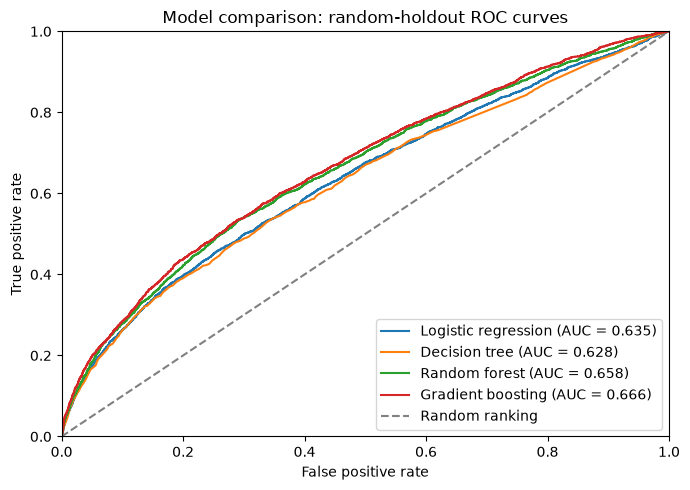

In [101]:
# Compare overall discrimination on the same random holdout.
fig, ax = plt.subplots(figsize=(7, 5))

for name in [
    "Logistic regression",
    "Decision tree",
    "Random forest",
    "Gradient boosting",
]:
    probability = predictions[name, "Random"]
    false_positive_rate, true_positive_rate, _ = roc_curve(
        random_test["low_review_2"], probability
    )
    auc = roc_auc_score(random_test["low_review_2"], probability)
    ax.plot(
        false_positive_rate,
        true_positive_rate,
        label=f"{name} (AUC = {auc:.3f})",
    )

ax.plot([0, 1], [0, 1], "--", color="gray", label="Random ranking")
ax.set(
    xlabel="False positive rate",
    ylabel="True positive rate",
    title="Model comparison: random-holdout ROC curves",
    xlim=(0, 1),
    ylim=(0, 1),
)
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

### Selected Model: Cumulative Gains

The random-holdout gains curve shows the share of low-review outcomes captured as monitoring expands through the highest-risk orders. The diagonal represents random selection; the marked top decile illustrates a hypothetical monitoring capacity.

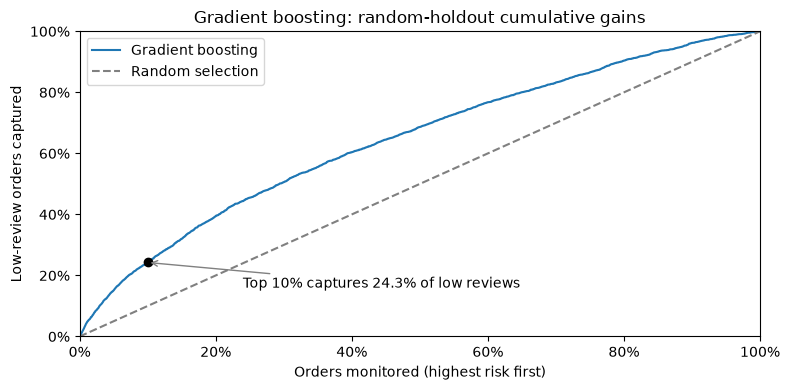

In [102]:
# Show cumulative low-review capture in the primary random holdout.
gains_orders = pd.DataFrame({
    "low_review": random_test["low_review_2"].to_numpy(),
    "risk": predictions["Gradient boosting", "Random"],
}).sort_values("risk", ascending=False, kind="stable")

monitored_share = np.arange(1, len(gains_orders) + 1) / len(gains_orders)
captured_share = (
    gains_orders["low_review"].cumsum().to_numpy()
    / gains_orders["low_review"].sum()
)
top_n = int(np.ceil(len(gains_orders) * 0.10))
top_capture = captured_share[top_n - 1]

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(
    np.r_[0, monitored_share],
    np.r_[0, captured_share],
    label="Gradient boosting",
)
ax.plot([0, 1], [0, 1], "--", color="gray", label="Random selection")
ax.scatter(monitored_share[top_n - 1], top_capture, color="black", zorder=3)
ax.annotate(
    f"Top 10% captures {top_capture:.1%} of low reviews",
    (monitored_share[top_n - 1], top_capture),
    xytext=(0.24, 0.16),
    arrowprops={"arrowstyle": "->", "color": "gray"},
)
ax.set(
    xlabel="Orders monitored (highest risk first)",
    ylabel="Low-review orders captured",
    title="Gradient boosting: random-holdout cumulative gains",
    xlim=(0, 1),
    ylim=(0, 1),
)
ax.set_xticks(np.linspace(0, 1, 6), labels=["0%", "20%", "40%", "60%", "80%", "100%"])
ax.set_yticks(np.linspace(0, 1, 6), labels=["0%", "20%", "40%", "60%", "80%", "100%"])
ax.legend()
plt.tight_layout()
plt.show()

### Chronological Evaluation

Gradient boosting was selected based on the randomized model comparison.
To assess performance on later orders, the model is refitted using the
same hyperparameters on orders with labels observable before May 1, 2018,
and evaluated on subsequent purchases with at least 60 days of potential
review follow-up.

This out-of-time evaluation provides a more realistic assessment of
forward-looking risk ranking than the randomized holdout.

In [104]:
# Refit gradient boosting on chronologically eligible training data.
sensitivity_model = clone(candidates["Gradient boosting"])

sensitivity_model.fit(
    chronological_train[feature_cols],
    chronological_train["low_review_2"],
)

models["Gradient boosting", "Chronological"] = sensitivity_model

probability = sensitivity_model.predict_proba(
    chronological_test[feature_cols]
)[:, 1]

predictions["Gradient boosting", "Chronological"] = probability

actual = chronological_test["low_review_2"]

# Overall evaluation metrics.
model_metrics.loc[len(model_metrics)] = {
    "model": "Gradient boosting",
    "evaluation": "Chronological",
    "prevalence": actual.mean(),
    "ap": average_precision_score(actual, probability),
    "roc_auc": roc_auc_score(actual, probability),
}

# Rank orders by predicted risk.
ranked = pd.DataFrame(
    {"actual": actual.to_numpy(), "probability": probability}
).sort_values("probability", ascending=False, kind="stable")

# Evaluate cumulative monitoring capacities.
for fraction in [0.05, 0.10, 0.20, 0.30]:
    count = int(np.ceil(len(ranked) * fraction))
    selected = ranked.head(count)
    precision = selected["actual"].mean()

    capacity_results.loc[len(capacity_results)] = {
        "model": "Gradient boosting",
        "evaluation": "Chronological",
        "capacity": fraction,
        "orders_monitored": count,
        "low_reviews_captured": selected["actual"].sum(),
        "capture": selected["actual"].sum() / actual.sum(),
        "precision": precision,
        "lift": precision / actual.mean(),
    }

print("Gradient boosting: randomized vs. chronological evaluation")

display(
    model_metrics.loc[model_metrics["model"].eq("Gradient boosting")]
    .drop(columns="model")
    .round(4)
)

display(
    capacity_results.loc[
        capacity_results["model"].eq("Gradient boosting")
        & capacity_results["capacity"].eq(0.10)
    ]
    .drop(columns=["model", "capacity"])
    .round(4)
)

Gradient boosting: randomized vs. chronological evaluation


,evaluation,prevalence,ap,roc_auc
3,Random,0.142,0.283,0.666
4,Chronological,0.109,0.182,0.593


,evaluation,orders_monitored,low_reviews_captured,capture,precision,lift
13,Random,1959,674,0.242,0.344,2.425
17,Chronological,2561,575,0.205,0.225,2.053


On the later-period evaluation, gradient boosting achieves AP **0.182** and ROC-AUC **0.593**, compared with AP **0.283** and ROC-AUC **0.666** in the random holdout. The highest-ranked 10% of later orders contains **575** eventual low-review cases, approximately **20.5%** of all low-review cases in that evaluation. Its low-review prevalence is approximately **22.5%**, compared with **10.9%** overall (**2.05× lift**). The chronological population's lower low-review prevalence also affects the comparison of AP across evaluations.

This demonstrates concentration above random selection; the simple-rule comparison below evaluates whether the model adds value beyond item count. The chronological fit uses only labels available before the cutoff, but model selection used the broader random-split workflow and the holdouts had already been inspected. These results are therefore a retrospective temporal sensitivity check rather than a fully independent prospective evaluation.


#### Selected Model: Risk by Predicted Decile

The chronological holdout is divided into ten groups ranked by predicted
low-review risk. Lift compares each group's observed low-review rate with
the overall chronological prevalence. A lift above 1 indicates greater
risk than the population average.

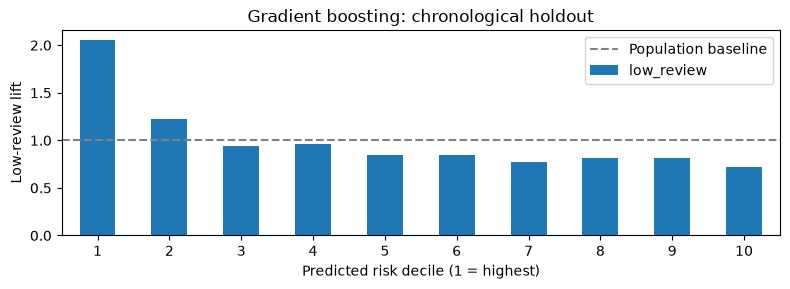

In [105]:
# Decile 1 contains the highest predicted-risk orders.
ranked_orders = pd.DataFrame({
    "low_review": chronological_test["low_review_2"].to_numpy(),
    "risk": predictions["Gradient boosting", "Chronological"],
}).sort_values("risk", ascending=False, kind="stable")

ranked_orders["decile"] = (
    np.arange(len(ranked_orders)) * 10 // len(ranked_orders) + 1
)

decile_lift = (
    ranked_orders.groupby("decile")["low_review"].mean()
    / ranked_orders["low_review"].mean()
)

decile_lift.plot.bar(figsize=(8, 3), rot=0)

plt.axhline(1, color="gray", linestyle="--", label="Population baseline")
plt.xlabel("Predicted risk decile (1 = highest)")
plt.ylabel("Low-review lift")
plt.title("Gradient boosting: chronological holdout")
plt.legend()
plt.tight_layout()
plt.show()

#### Item-count Benchmark Across Both Holdouts

This comparison assesses whether the selected model captures more low reviews than item-count ranking at the same monitoring capacity. Both holdouts target the top 10% of orders, rounded up. Capture is the percentage of actual low-review cases selected; differences are percentage points of capture, not changes in review prevalence. Cutoff ties use exact expected capture under uniform selection, and random selection is shown by its expectation. The supporting calculations and separate benchmark tables are retained in collapsed cells; the combined table is the main comparison.


In [103]:
# Expected capture with uniform selection among orders tied at the cutoff.
def item_benchmark_capture(actual, scores, count):
    scores = np.asarray(scores)
    cutoff = np.sort(scores)[-count]
    above, tied = scores > cutoff, scores == cutoff
    captured = actual[above].sum() + (count - above.sum()) * actual[tied].mean()
    return 100 * captured / actual.sum()

random_rule_actual = random_test["low_review_2"].to_numpy()
random_rule_count = int(np.ceil(len(random_rule_actual) * 0.10))
random_rule_scores = {
    "Random selection (expected)": np.zeros(len(random_rule_actual)),
    "Item-count ranking": random_test["item_count"].to_numpy(),
    "Final predictive model": predictions["Gradient boosting", "Random"],
}
random_rule_comparison = pd.DataFrame({
    "Strategy": list(random_rule_scores),
    "Orders targeted (%)": 100 * random_rule_count / len(random_rule_actual),
    "Low-review cases captured (%)": [
        item_benchmark_capture(random_rule_actual, scores, random_rule_count)
        for scores in random_rule_scores.values()
    ],
})
display(random_rule_comparison.round(2))


,Strategy,Orders targeted (%),Low-review cases captured (%)
0,Random selection (expected),10.000,10.000
1,Item-count ranking,10.000,20.750
2,Final predictive model,10.000,24.250


In [106]:
rule_actual = chronological_test["low_review_2"].to_numpy()
rule_count = int(np.ceil(len(rule_actual) * 0.10))
rule_scores = {
    "Random selection (expected)": np.zeros(len(rule_actual)),
    "Item-count ranking": chronological_test["item_count"].to_numpy(),
    "Seller-count ranking": chronological_test["unique_seller_count"].to_numpy(),
    "Final predictive model": predictions["Gradient boosting", "Chronological"],
}
rule_comparison = pd.DataFrame({
    "Strategy": list(rule_scores),
    "Orders targeted (%)": 100 * rule_count / len(rule_actual),
    "Low-review cases captured (%)": [
        item_benchmark_capture(rule_actual, scores, rule_count)
        for scores in rule_scores.values()
    ],
})
display(rule_comparison.round(2))


,Strategy,Orders targeted (%),Low-review cases captured (%)
0,Random selection (expected),10.000,10.000
1,Item-count ranking,10.000,21.640
2,Seller-count ranking,10.000,14.410
3,Final predictive model,10.000,20.540


In [107]:
# Combined tie-adjusted benchmark results.
benchmark_summary = pd.concat({
    "Random holdout": random_rule_comparison.set_index("Strategy")[
        "Low-review cases captured (%)"
    ],
    "Chronological holdout": rule_comparison.set_index("Strategy")[
        "Low-review cases captured (%)"
    ],
}, axis=1).reindex([
    "Random selection (expected)", "Item-count ranking", "Final predictive model",
]).T
benchmark_summary["Model minus item rule (pp)"] = (
    benchmark_summary["Final predictive model"]
    - benchmark_summary["Item-count ranking"]
)
display(benchmark_summary.round(2))


Strategy,Random selection (expected),Item-count ranking,Final predictive model,Model minus item rule (pp)
Random holdout,10.000,20.750,24.250,3.500
Chronological holdout,10.000,21.640,20.540,-1.100


The model captures **3.50 percentage points more** low-review cases than item count on the random holdout (**24.25% versus 20.75%**), but **1.10 points fewer** on the chronological holdout (**20.54% versus 21.64%**). Its incremental targeting advantage does not persist into the later period at the evaluated top-10% capacity. Seller-count ranking captures **14.41%** on the chronological holdout, versus **10.00%** expected from random selection.

These results support item count as a strong, simple targeting baseline. Lift above random selection alone does not establish added value over that rule. The comparisons do not establish equivalent performance at other capacities, statistical significance, or the benefit of an intervention.


## Model Interpretation

### Permutation Importance

Permutation importance measures how much the selected gradient boosting
model's average precision decreases when each predictor is shuffled
individually in the chronological holdout.

Larger decreases indicate greater contributions to predictive performance
in this evaluation population. Correlated predictors may share importance,
and these results do not establish causal relationships.

In [109]:
permutation = permutation_importance(
    models["Gradient boosting", "Chronological"],
    chronological_test[feature_cols],
    chronological_test["low_review_2"],
    scoring="average_precision",
    n_repeats=5,
    random_state=1,
)

permutation_top = pd.DataFrame(
    {
        "feature": feature_cols,
        "mean_ap_decrease": permutation.importances_mean,
        "std_ap_decrease": permutation.importances_std,
    }
).sort_values("mean_ap_decrease", ascending=False).head(15)

display(permutation_top.round(4))

,feature,mean_ap_decrease,std_ap_decrease
2,item_count,0.048,0.002
4,unique_seller_count,0.018,0.001
11,promised_delivery_days,0.005,0.001
15,any_cross_state,0.005,0.001
0,merchandise_value,0.004,0.000
12,customer_state,0.004,0.001
5,total_product_weight_g,0.003,0.001
8,avg_product_description_length,0.002,0.001
1,freight_value,0.002,0.001
10,freight_share,0.001,0.001


### Interpretation

Item count and distinct seller count lead the chronological AP-based permutation importance, with decreases of approximately **0.048** and **0.018**, respectively. They contribute most to this model's predictive ranking in the evaluated population.

Other predictors, including promised delivery time and customer geography, contribute more modestly. Permutation importance does not establish the direction or cause of an association, and correlated predictors can share importance. The simple-rule benchmark remains necessary: strong feature importance does not establish that the model ranks orders better than item count alone.


### Interpretation Implications

Item count and seller count lead the chronological AP-based permutation results. Purchase month is absent from the displayed top 15, so this output does not support assigning it a ninth-place rank. The May-onward chronological test also cannot validate February/March effects.

The February/March elevation is concentrated in 2018, while July/August rates are reasonably consistent across 2017–2018. Month is interpreted as historical context rather than established seasonality. These descriptive comparisons do not explain the cause; months with only 1–3 reviewed orders have unstable rates. The diagnostics qualify the interpretation without changing the model, predictors, or evaluation protocol.

The supporting month-year distributions are documented in the Purchase Month-year Diagnostic subsection of `02_eda.ipynb`.


## Customer-Experience Risk Beyond Late Delivery

Late delivery is strongly associated with low reviews, but most low-reviewed
orders with valid observed delivery timing arrived by their promised date.

This retrospective sensitivity analysis examines whether the selected
placement-time model retains predictive signal among orders that were
eventually delivered on time.

The analysis compares the primary chronological model's performance on the
full holdout and timely-delivery subgroup, then refits the same gradient
boosting pipeline using only timely chronological training orders.

All predictors and hyperparameters remain unchanged. Actual delivery timing
is used only to define the retrospective subgroup, not as a model predictor
or proposed deployment criterion.

In [110]:
# Identify orders delivered on or before their promised calendar date.
delivery_dates = (
    olist_df.groupby("order_id")["order_delivered_customer_date"]
    .first()
)

order_df["timely_delivery"] = (
    order_df["order_id"].map(delivery_dates).dt.normalize()
    <= order_df["order_estimated_delivery_date"].dt.normalize()
)

timely_order_ids = set(
    order_df.loc[order_df["timely_delivery"], "order_id"]
)

chrono_train, chrono_test = evaluation_sets["Chronological"]

train_timely = chrono_train.loc[
    chrono_train["order_id"].isin(timely_order_ids)
].copy()

test_timely_mask = chrono_test["order_id"].isin(timely_order_ids)
test_timely = chrono_test.loc[test_timely_mask].copy()

print(
    f"Timely chronological training: {len(train_timely):,} orders "
    f"({train_timely['low_review_2'].mean():.2%} low reviews)"
)

print(
    f"Timely chronological test: {len(test_timely):,} orders "
    f"({test_timely['low_review_2'].mean():.2%} low reviews)"
)

Timely chronological training: 62,276 orders (9.58% low reviews)
Timely chronological test: 24,149 orders (8.34% low reviews)


### Chronological Sensitivity Analysis

Three evaluations distinguish the effects of restricting the test population
from those of restricting the training population:

1. Original model evaluated on all chronological test orders.
2. Original model evaluated only on timely chronological test orders.
3. Timely-only refit evaluated on those same timely test orders.

Average precision, ROC-AUC, and top-decile lift and capture are reported.
Differences in low-review prevalence are considered when comparing results.

In [111]:
def ranking_metrics(y_true, y_prob):
    y_true = pd.Series(y_true).reset_index(drop=True)
    prevalence = y_true.mean()

    top_n = int(np.ceil(len(y_true) * 0.10))
    top_idx = np.argsort(-np.asarray(y_prob), kind="stable")[:top_n]
    top_rate = y_true.iloc[top_idx].mean()

    return {
        "Prevalence": prevalence,
        "AP": average_precision_score(y_true, y_prob),
        "ROC-AUC": roc_auc_score(y_true, y_prob),
        "Top 10% lift": top_rate / prevalence,
        "Top 10% capture": y_true.iloc[top_idx].sum() / y_true.sum(),
    }

In [112]:
# Refit the selected pipeline using timely chronological training orders.
timely_model = clone(models["Gradient boosting", "Chronological"])

timely_model.fit(
    train_timely[feature_cols],
    train_timely["low_review_2"],
)

timely_prob = timely_model.predict_proba(
    test_timely[feature_cols]
)[:, 1]

# Original chronological predictions, preserving test-row alignment.
primary_prob = predictions["Gradient boosting", "Chronological"]
primary_timely_prob = primary_prob[test_timely_mask.to_numpy()]

comparisons = {
    "Primary / full holdout": (
        chrono_test["low_review_2"],
        primary_prob,
    ),
    "Primary / timely holdout": (
        test_timely["low_review_2"],
        primary_timely_prob,
    ),
    "Timely refit / timely holdout": (
        test_timely["low_review_2"],
        timely_prob,
    ),
}

timely_results = pd.DataFrame({
    name: ranking_metrics(y_true, y_prob)
    for name, (y_true, y_prob) in comparisons.items()
}).T

display(timely_results.round(4))

,Prevalence,AP,ROC-AUC,Top 10% lift,Top 10% capture
Primary / full holdout,0.109,0.182,0.593,2.053,0.205
Primary / timely holdout,0.083,0.172,0.621,2.473,0.247
Timely refit / timely holdout,0.083,0.182,0.633,2.706,0.271


#### Risk Concentration Among Timely Deliveries

Top-decile lift compares the monitored group with its own evaluation population. The full and timely populations have different low-review prevalence, so taller bars do not by themselves indicate better absolute precision. Timely delivery defines a retrospective subgroup, not a placement-time eligibility rule.

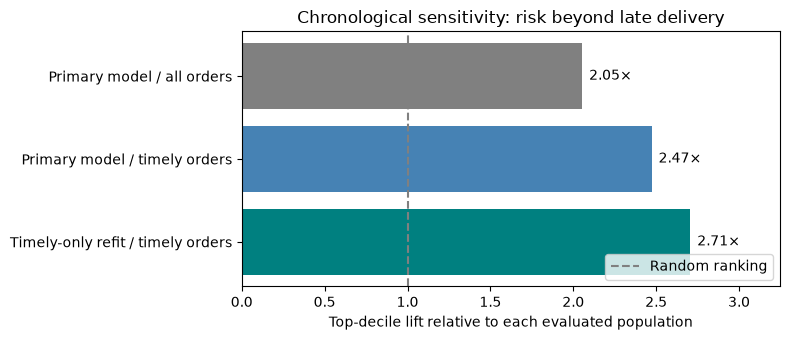

In [113]:
# Top-decile concentration across sensitivity populations.
lift = timely_results["Top 10% lift"]
labels = [
    "Primary model / all orders",
    "Primary model / timely orders",
    "Timely-only refit / timely orders",
]

fig, ax = plt.subplots(figsize=(8, 3.5))
bars = ax.barh(labels, lift, color=["gray", "steelblue", "teal"])
ax.bar_label(bars, labels=[f"{value:.2f}×" for value in lift], padding=5)
ax.axvline(1, color="gray", linestyle="--", label="Random ranking")
ax.set(
    xlabel="Top-decile lift relative to each evaluated population",
    title="Chronological sensitivity: risk beyond late delivery",
    xlim=(0, lift.max() * 1.2),
)
ax.invert_yaxis()
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

### Predictive Characteristics Among Timely Deliveries

Permutation importance is calculated for the timely-only chronological
refit using average precision on the timely chronological test population.

This examines whether the leading predictive characteristics remain
consistent after restricting the analysis to orders that ultimately
met their delivery promise.

In [114]:
timely_importance = permutation_importance(
    timely_model,
    test_timely[feature_cols],
    test_timely["low_review_2"],
    scoring="average_precision",
    n_repeats=5,
    random_state=1,
)

timely_importance_df = pd.DataFrame({
    "feature": feature_cols,
    "mean_ap_decrease": timely_importance.importances_mean,
    "std_ap_decrease": timely_importance.importances_std,
}).sort_values("mean_ap_decrease", ascending=False)

display(timely_importance_df.head(10).round(4))

,feature,mean_ap_decrease,std_ap_decrease
2,item_count,0.075,0.002
4,unique_seller_count,0.020,0.001
11,promised_delivery_days,0.009,0.001
1,freight_value,0.005,0.002
5,total_product_weight_g,0.004,0.001
8,avg_product_description_length,0.004,0.002
60,category_informatica_acessorios,0.003,0.000
7,avg_product_name_length,0.003,0.001
0,merchandise_value,0.003,0.000
10,freight_share,0.002,0.002


### Comparison of Leading Predictors

The charts show the top five permutation importances on a shared scale. The comparison concerns leading features and their relative prominence; magnitudes reflect different fitted models and evaluation populations and do not establish causal effects.

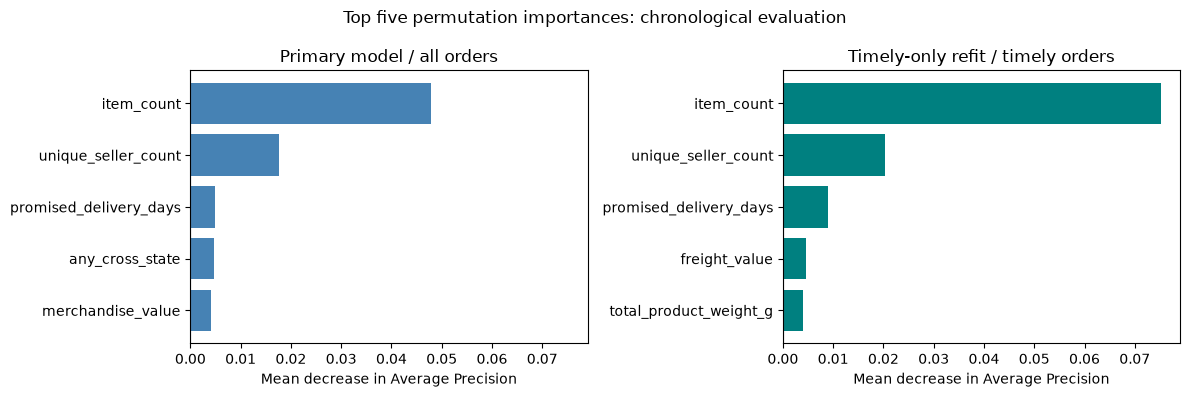

In [115]:
# AP-based permutation importances across evaluation populations.
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True)

for ax, importance, title, color in zip(
    axes,
    [permutation_top, timely_importance_df],
    ["Primary model / all orders", "Timely-only refit / timely orders"],
    ["steelblue", "teal"],
):
    top_features = importance.nlargest(5, "mean_ap_decrease")
    ax.barh(
        top_features["feature"],
        top_features["mean_ap_decrease"],
        color=color,
    )
    ax.invert_yaxis()
    ax.set_title(title)
    ax.set_xlabel("Mean decrease in Average Precision")
    ax.axvline(0, color="gray", linewidth=0.8)

fig.suptitle("Top five permutation importances: chronological evaluation")
plt.tight_layout()
plt.show()

### Interpretation

The primary placement-time model retains useful ranking signal among orders that ultimately arrive on time. On the timely chronological holdout, its highest-risk 10% captures 24.7% of low-review outcomes (2.47× lift). The timely-only refit captures 27.1% on the same test population (2.71× lift). This is an observed improvement in top-decile concentration, not evidence that the difference is statistically reliable. Timely delivery defines a retrospective diagnostic subgroup; it is not known at placement.

The importance charts show a consistent leading pattern: item count, seller count, and promised delivery days are the three strongest predictors in both evaluations. Cross-state participation and merchandise value complete the primary model's top five, while freight value and product weight complete the timely-only refit's top five. Basket complexity therefore remains informative even when eventual late delivery is excluded from evaluation.

Permutation importance measures contribution to AP, not the direction or cause of an association. The different models and evaluation populations also prevent interpreting larger importance values as a direct improvement or stronger causal effect.

These findings support investigating customer-experience risk beyond delivery delays, particularly complex-order processes. However, at top-10% capacity the primary model captures fewer low reviews than item-count ranking on the full chronological holdout (20.54% versus 21.64%). The timely-subgroup results do not demonstrate incremental value over a subgroup-specific item-count rule, which was not evaluated here. Operational model use would require evidence of added value over simple targeting rules and a prospective assessment of support interventions.

### Investigating Basket Complexity and Product Mix

The model's importance results motivate this exploratory follow-up. Comparisons describe low-review rates by basket size and seller count, then examine whether the basket pattern persists within product categories and among timely deliveries. They do not independently validate the model or isolate causal effects.

Item counts of four or more are grouped for display. Category and product comparisons count each order once per category or listing; mixed baskets can appear in several groups. Category names follow the source dataset. Support thresholds are descriptive safeguards, not significance tests. No predictors, populations, or fitted models are changed.

reviewed_orders  low_review_rate
population       items sellers                                           
All reviewed     1     Single seller               88227            0.127
                 2     Multiple sellers              949            0.458
                       Single seller                6491            0.235
                 3     Multiple sellers              201            0.473
                       Single seller                1099            0.266
                 4     Multiple sellers              114            0.597
                       Single seller                 836            0.321
Timely delivered 1     Single seller               80411            0.075
                 2     Multiple sellers              935            0.454
                       Single seller                6001            0.197
                 3     Multiple sellers              200            0.470
                       Single seller                1024            0.233
                 4     Multiple sellers              114            0.597
                       Single seller                 763            0.281

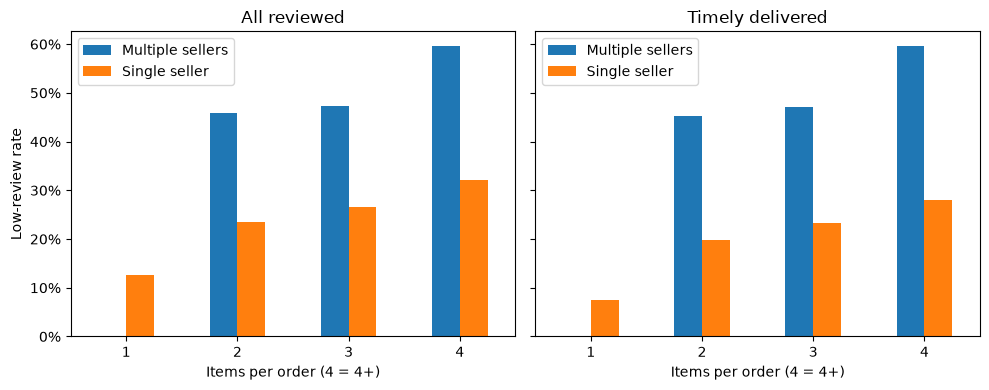

In [116]:
# Count each reviewed order once; delivery timing is retrospective context.
basket_orders = olist_df.groupby("order_id").agg(
    item_count=("order_item_id", "size"),
    seller_count=("seller_id", "nunique"),
    review_score=("last_review_score", "first"),
    delivered=("order_delivered_customer_date", "first"),
    promised=("order_estimated_delivery_date", "first"),
).dropna(subset=["review_score"])
basket_orders["low_review"] = basket_orders["review_score"].le(2)
basket_orders["timely"] = (
    basket_orders["delivered"].dt.normalize()
    <= basket_orders["promised"].dt.normalize()
)
basket_orders["items"] = basket_orders["item_count"].clip(upper=4)
basket_orders["sellers"] = np.where(
    basket_orders["seller_count"].eq(1), "Single seller", "Multiple sellers"
)

basket_rates = pd.concat({
    "All reviewed": basket_orders,
    "Timely delivered": basket_orders.loc[basket_orders["timely"]],
}, names=["population"]).groupby(
    ["population", "items", "sellers"]
).agg(
    reviewed_orders=("low_review", "size"),
    low_review_rate=("low_review", "mean"),
)
display(basket_rates.round(4))

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, population in zip(axes, ["All reviewed", "Timely delivered"]):
    basket_rates.loc[population, "low_review_rate"].unstack().plot.bar(
        ax=ax, rot=0
    )
    ax.set_title(population)
    ax.set_xlabel("Items per order (4 = 4+)")
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
    ax.legend(title=None)
axes[0].set_ylabel("Low-review rate")
plt.tight_layout()
plt.show()

#### Basket Size and Seller Participation

Item count is the number of order-item rows, including repeated products, rather than distinct products or a separate quantity-field total. Distinct seller count is the number of unique seller IDs per order. The baseline contains no duplicate order/item keys. These three groups cover all reviewed orders in the existing basket analysis; shares use that reviewed population, and low-review rates use its existing 1–2-star outcome. The correlation describes how the counts move together, not independent or causal effects.


In [117]:
basket_group_labels = [
    "Single-item, single-seller",
    "Multi-item, single-seller",
    "Multi-item, multi-seller",
]
basket_groups = np.select(
    [basket_orders["item_count"].eq(1), basket_orders["seller_count"].eq(1)],
    basket_group_labels[:2],
    default=basket_group_labels[2],
)
basket_group_summary = (
    basket_orders.groupby(basket_groups)
    .agg(
        order_count=("low_review", "size"),
        low_review_rate=("low_review", "mean"),
    )
    .reindex(basket_group_labels)
    .rename_axis("Order group")
)
basket_group_summary.insert(
    1, "share_of_reviewed_orders_pct",
    100 * basket_group_summary["order_count"] / len(basket_orders),
)
basket_group_summary["low_review_rate"] *= 100
basket_group_summary = basket_group_summary.rename(
    columns={"low_review_rate": "low_review_rate_pct"}
)
display(basket_group_summary.round(2))
print(
    "Item-count / seller-count correlation: "
    f"{basket_orders['item_count'].corr(basket_orders['seller_count']):.3f}"
)


,order_count,share_of_reviewed_orders_pct,low_review_rate_pct
Order group,,,
"Single-item, single-seller",88227,90.100,12.710
"Multi-item, single-seller",8426,8.610,24.720
"Multi-item, multi-seller",1264,1.290,47.310


Item-count / seller-count correlation: 0.285


#### Investigating Order Complexity Beyond Delivery Delays

Using the same three order-composition groups as the basket EDA, this retrospective comparison includes all reviewed orders delivered on or before their promised calendar date, not only the chronological holdout. Percentages use this timely-delivered population. Delivery timing defines descriptive context and does not change model eligibility or predictors.


In [108]:
# Use observed delivery timing only for this retrospective comparison.
timely_composition = order_df.loc[
    order_df["order_id"].isin(olist_df.loc[
        olist_df["order_delivered_customer_date"].dt.normalize()
        <= olist_df["order_estimated_delivery_date"].dt.normalize(),
        "order_id",
    ])
]
timely_group_labels = [
    "Single-item, single-seller",
    "Multi-item, single-seller",
    "Multi-item, multi-seller",
]
timely_groups = np.select(
    [
        timely_composition["item_count"].eq(1),
        timely_composition["unique_seller_count"].eq(1),
    ],
    timely_group_labels[:2],
    default=timely_group_labels[2],
)
timely_composition_summary = (
    timely_composition.groupby(timely_groups)
    .agg(
        order_count=("low_review_2", "size"),
        low_review_rate_pct=("low_review_2", "mean"),
    )
    .reindex(timely_group_labels)
    .rename_axis("Order group")
)
timely_composition_summary.insert(
    1, "share_of_timely_orders_pct",
    100 * timely_composition_summary["order_count"] / len(timely_composition),
)
timely_composition_summary["low_review_rate_pct"] *= 100
display(timely_composition_summary.round(2))


,order_count,share_of_timely_orders_pct,low_review_rate_pct
Order group,,,
"Single-item, single-seller",80411,89.900,7.550
"Multi-item, single-seller",7788,8.710,21.010
"Multi-item, multi-seller",1249,1.400,46.920


Among timely deliveries, low-review rates rise from **7.6%** for single-item, single-seller orders to **21.0%** for multi-item, single-seller orders and **46.9%** for multi-item, multi-seller orders. The order-complexity pattern therefore persists when late deliveries are excluded. Multi-seller orders remain a small subgroup; these unadjusted rates do not establish causation or incremental model value over the simple rules.


#### Seller Concentration and Order-complexity Robustness

This descriptive check uses reviewed orders delivered on or before their estimated calendar date, with both dates observed. Item bands are 1, 2, 3, and 4+ order-item rows. Low reviews use the established latest answered 1–2-star outcome. Each order contributes once to rates; a seller-order association records one distinct seller participating in one order.

Activity leaders are ranked by their unique-order involvement within timely multi-seller orders, without using review outcomes. Top 1, 5, and 10 are fixed descriptive sensitivity checks, not optimized cutoffs. Activity ties follow seller-ID order. The low-review concentration ranking instead uses each seller's low-reviewed-order count, breaking ties by activity then seller ID; it is descriptive only. The first table uses the same five activity leaders across item bands. Coverage counts orders involving any selected seller once, so seller participation percentages need not add to 100%.

For robustness, every timely order involving a selected activity leader is removed from both single- and multi-seller groups before comparing rates within item-count bands. Missing multi-seller rates for one-item orders are structural: one item cannot involve multiple sellers. Reviews belong to orders and cannot identify which participating seller, if any, caused dissatisfaction.


#### Findings for the Order-complexity Narrative

The 1,249 timely multi-seller orders involve **819 distinct sellers** and **2,564 seller-order associations**. Their 586 low-reviewed orders involve **535 sellers**, while 663 other-reviewed orders involve **572 sellers**; **288 sellers appear in both outcome groups**. The 2-, 3-, and 4+-item groups involve 695, 259, and 179 sellers respectively, with overlap across groups.

The ten activity leaders participate in **26.7% of all timely multi-seller orders**, **27.6% of low-reviewed orders**, and **25.8% of other-reviewed orders**. The ten sellers with the most low-reviewed-order associations collectively participate in **29.0% of low-reviewed orders**. These shares indicate some concentration but do not suggest that a handful of sellers accounts for most low-review cases. Among the ten activity leaders, individual involvement differences between low and other outcomes range from approximately **−1.6 to +1.6 percentage points**; this is not an exhaustive search for problematic sellers.

After excluding orders involving the ten activity leaders, multi-seller low-review rates remain **45.2%, 43.3%, and 61.3%** for 2, 3, and 4+ items, versus **19.7%, 23.0%, and 28.1%** for single-seller orders in the same bands. The corresponding gaps remain **25.5, 20.3, and 33.3 percentage points**. The remaining multi-seller groups contain 714, 127, and 75 orders, so larger baskets still have limited support.

This sensitivity check supports the descriptive interpretation: the elevated low-review rate among timely multi-seller orders is not explained solely by the most frequently represented sellers. It does not establish that multiple sellers cause dissatisfaction, isolate coordination effects, or rule out other seller, product, period, or customer differences. Whole-order ratings also prevent assigning responsibility to individual sellers.


In [118]:
# Reuse the reviewed order-level basket data and calendar-date timely flag.
complexity_orders = basket_orders.loc[
    basket_orders["timely"], ["item_count", "seller_count", "low_review"],
].reset_index()
complexity_orders["item_band"] = complexity_orders["item_count"].clip(upper=4)
seller_links = olist_df[["order_id", "seller_id"]].drop_duplicates()
complexity_multi = complexity_orders.loc[complexity_orders["seller_count"].gt(1)]
complexity_links = seller_links.merge(
    complexity_multi[["order_id", "item_band", "low_review"]],
    on="order_id", validate="many_to_one",
)
# One seller-order association per row; rank sellers without using outcomes.
seller_frequency = (
    complexity_links.groupby("seller_id").agg(
        orders=("order_id", "size"), low_review_orders=("low_review", "sum"),
    )
    .sort_values("orders", ascending=False, kind="stable")
)
seller_frequency["other_review_orders"] = (
    seller_frequency["orders"] - seller_frequency["low_review_orders"]
)
complexity_support = []
for band, group in complexity_multi.groupby("item_band"):
    links = complexity_links.loc[complexity_links["item_band"].eq(band)]
    top_ids = seller_frequency.head(5).index
    complexity_support.append({
        "Items (4 = 4+)": band,
        "Unique orders": len(group),
        "Unique sellers": links["seller_id"].nunique(),
        "Seller-order associations": len(links),
        "Low-reviewed orders": int(group["low_review"].sum()),
        "Low-review rate (%)": 100 * group["low_review"].mean(),
        "Orders involving top 5 sellers (%)": 100 * group["order_id"].isin(
            links.loc[links["seller_id"].isin(top_ids), "order_id"]
        ).mean(),
    })
display(pd.DataFrame(complexity_support).set_index("Items (4 = 4+)").round(1))


,Unique orders,Unique sellers,Seller-order associations,Low-reviewed orders,Low-review rate (%),Orders involving top 5 sellers (%)
Items (4 = 4+),,,,,,
2,935,695,1870,424,45.300,15.700
3,200,259,432,94,47.000,28.500
4,114,179,262,68,59.600,21.900


In [119]:
# Count each order once even when it contains several selected sellers.
low_order_ids = complexity_multi.loc[
    complexity_multi["low_review"].eq(1), "order_id"
]
other_order_ids = complexity_multi.loc[
    complexity_multi["low_review"].eq(0), "order_id"
]
low_seller_frequency = seller_frequency.sort_values(
    "low_review_orders", ascending=False, kind="stable",
)
concentration_rows = []
for count in [1, 5, 10]:
    frequent_ids = seller_frequency.head(count).index
    frequent_orders = complexity_links.loc[
        complexity_links["seller_id"].isin(frequent_ids), "order_id"
    ].unique()
    low_ranked_orders = complexity_links.loc[
        complexity_links["seller_id"].isin(low_seller_frequency.head(count).index),
        "order_id",
    ].unique()
    concentration_rows.append({
        "Top sellers": count,
        "All orders involving activity leaders (%)": 100 * complexity_multi[
            "order_id"
        ].isin(frequent_orders).mean(),
        "Low orders involving activity leaders (%)": 100 * low_order_ids.isin(
            frequent_orders
        ).mean(),
        "Other orders involving activity leaders (%)": 100 * other_order_ids.isin(
            frequent_orders
        ).mean(),
        "Low orders involving low-review leaders (%)": 100 * low_order_ids.isin(
            low_ranked_orders
        ).mean(),
    })
print(
    f"Timely multi-seller orders: {len(complexity_multi):,}; "
    f"unique sellers: {len(seller_frequency):,}; "
    f"seller-order associations: {len(complexity_links):,}."
)
print(
    f"Low-reviewed orders: {len(low_order_ids):,}; contributing sellers: "
    f"{seller_frequency['low_review_orders'].gt(0).sum():,}. "
    f"Other-reviewed orders: {len(other_order_ids):,}; contributing sellers: "
    f"{seller_frequency['other_review_orders'].gt(0).sum():,}."
)
display(pd.DataFrame(concentration_rows).set_index("Top sellers").round(1))


Timely multi-seller orders: 1,249; unique sellers: 819; seller-order associations: 2,564.
Low-reviewed orders: 586; contributing sellers: 535. Other-reviewed orders: 663; contributing sellers: 572.


,All orders involving activity leaders (%),Low orders involving activity leaders (%),Other orders involving activity leaders (%),Low orders involving low-review leaders (%)
Top sellers,,,,
1,7.500,6.700,8.300,6.700
5,18.300,17.900,18.700,17.700
10,26.700,27.600,25.800,29.000


In [120]:
# Compare seller involvement in low versus other multi-seller orders.
seller_overlap = seller_frequency.head(10).copy()
seller_overlap["Low orders involving seller (%)"] = (
    100 * seller_overlap["low_review_orders"] / len(low_order_ids)
)
seller_overlap["Other orders involving seller (%)"] = (
    100 * seller_overlap["other_review_orders"] / len(other_order_ids)
)
seller_overlap["Low minus other involvement (pp)"] = (
    seller_overlap["Low orders involving seller (%)"]
    - seller_overlap["Other orders involving seller (%)"]
)
display(seller_overlap.rename(columns={
    "orders": "Seller-order associations", "low_review_orders": "Low orders",
    "other_review_orders": "Other orders",
}).round(1))


,Seller-order associations,Low orders,Other orders,Low orders involving seller (%),Other orders involving seller (%),Low minus other involvement (pp)
seller_id,,,,,,
4a3ca9315b744ce9f8e9374361493884,94,39,55,6.700,8.300,-1.600
1900267e848ceeba8fa32d80c1a5f5a8,45,19,26,3.200,3.900,-0.700
1835b56ce799e6a4dc4eddc053f04066,42,22,20,3.800,3.000,0.700
da8622b14eb17ae2831f4ac5b9dab84a,37,18,19,3.100,2.900,0.200
1f50f920176fa81dab994f9023523100,35,20,15,3.400,2.300,1.200
cca3071e3e9bb7d12640c9fbe2301306,32,20,12,3.400,1.800,1.600
1025f0e2d44d7041d6cf58b6550e0bfa,30,13,17,2.200,2.600,-0.300
6560211a19b47992c3666cc44a7e94c0,30,17,13,2.900,2.000,0.900
391fc6631aebcf3004804e51b40bcf1e,28,11,17,1.900,2.600,-0.700


In [121]:
# Exclude whole orders involving the activity leaders from both comparison groups.
robustness_rows = []
for count in [0, 1, 5, 10]:
    excluded_order_ids = seller_links.loc[
        seller_links["seller_id"].isin(seller_frequency.head(count).index),
        "order_id",
    ]
    retained = complexity_orders.loc[
        ~complexity_orders["order_id"].isin(excluded_order_ids)
    ]
    for band in [1, 2, 3, 4]:
        group = retained.loc[retained["item_band"].eq(band)]
        single = group.loc[group["seller_count"].eq(1), "low_review"]
        multi = group.loc[group["seller_count"].gt(1), "low_review"]
        robustness_rows.append({
            "Top sellers excluded": count,
            "Items (4 = 4+)": band,
            "Single-seller orders": len(single),
            "Single-seller low-review rate (%)": 100 * single.mean(),
            "Multi-seller orders": len(multi),
            "Multi-seller low-review rate (%)": 100 * multi.mean(),
            "Multi minus single (pp)": 100 * (multi.mean() - single.mean()),
        })
complexity_robustness = pd.DataFrame(robustness_rows).set_index([
    "Top sellers excluded", "Items (4 = 4+)",
])
display(complexity_robustness.round(1))


Single-seller orders  \
Top sellers excluded Items (4 = 4+)                         
0                    1                              80411   
                     2                               6001   
                     3                               1024   
                     4                                763   
1                    1                              79045   
                     2                               5895   
                     3                               1012   
                     4                                758   
5                    1                              76599   
                     2                               5427   
                     3                                918   
                     4                                693   
10                   1                              72547   
                     2                               5056   
                     3                                778   
                     4                                652   

                                     Single-seller low-review rate (%)  \
Top sellers excluded Items (4 = 4+)                                      
0                    1                                           7.500   
                     2                                          19.700   
                     3                                          23.300   
                     4                                          28.000   
1                    1                                           7.500   
                     2                                          19.700   
                     3                                          23.300   
                     4                                          28.100   
5                    1                                           7.600   
                     2                                          19.700   
                     3                                          23.100   
                     4                                          27.400   
10                   1                                           7.400   
                     2                                          19.700   
                     3                                          23.000   
                     4                                          28.100   

                                     Multi-seller orders  \
Top sellers excluded Items (4 = 4+)                        
0                    1                                 0   
                     2                               935   
                     3                               200   
                     4                               114   
1                    1                                 0   
                     2                               859   
                     3                               185   
                     4                               111   
5                    1                                 0   
                     2                               788   
                     3                               143   
                     4                                89   
10                   1                                 0   
                     2                               714   
                     3                               127   
                     4                                75   

                                     Multi-seller low-review rate (%)  \
Top sellers excluded Items (4 = 4+)                                     
0                    1                                            NaN   
                     2                                         45.300   
                     3                                         47.000   
                     4                                         59.600   
1                    1                                            NaN   
             

In [122]:
# Deduplicate order-category pairs so repeated units do not inflate rates.
category_orders = (
    olist_df[["order_id", "product_category_name"]]
    .fillna({"product_category_name": "unknown"})
    .drop_duplicates()
    .join(basket_orders[["item_count", "low_review", "timely"]], on="order_id")
    .dropna(subset=["low_review"])
)
category_orders["low_review"] = category_orders["low_review"].astype(int)
category_orders["basket"] = np.where(
    category_orders["item_count"].eq(1), "Single item", "Multiple items"
)
category_rates = category_orders.groupby("product_category_name").agg(
    reviewed_orders=("low_review", "size"),
    low_reviews=("low_review", "sum"),
    low_review_rate=("low_review", "mean"),
).sort_values("reviewed_orders", ascending=False)
display(category_rates.head(10).round(4))

category_basket_rates = pd.concat({
    "All reviewed": category_orders,
    "Timely delivered": category_orders.loc[category_orders["timely"]],
}, names=["population"]).groupby(
    ["population", "product_category_name", "basket"]
).agg(
    reviewed_orders=("low_review", "size"),
    low_review_rate=("low_review", "mean"),
)
# Require 100 reviewed orders in each basket group for this comparison.
category_counts = category_basket_rates["reviewed_orders"].unstack("basket")
category_comparison = category_basket_rates["low_review_rate"].unstack("basket")
category_comparison = category_comparison.loc[
    category_counts.ge(100).all(axis=1)
]
category_comparison["difference_pp"] = 100 * (
    category_comparison["Multiple items"] - category_comparison["Single item"]
)
print("Categories with higher multi-item low-review rates / eligible categories:")
for population, group in category_comparison.groupby(level="population"):
    print(population, int(group["difference_pp"].gt(0).sum()), "/", len(group))

top_categories = category_rates.head(10).index
display(category_comparison.loc[
    category_comparison.index.get_level_values("product_category_name")
    .isin(top_categories)
].round(4))

,reviewed_orders,low_reviews,low_review_rate
product_category_name,,,
cama_mesa_banho,9313,1561,0.168
beleza_saude,8771,1114,0.127
esporte_lazer,7669,998,0.130
informatica_acessorios,6649,1070,0.161
moveis_decoracao,6398,1067,0.167
utilidades_domesticas,5843,772,0.132
relogios_presentes,5576,848,0.152
telefonia,4168,645,0.155
automotivo,3877,562,0.145


Categories with higher multi-item low-review rates / eligible categories:
All reviewed 21 / 21
Timely delivered 21 / 21


basket                                   Multiple items  Single item  \
population       product_category_name                                 
All reviewed     automotivo                       0.275        0.135   
                 beleza_saude                     0.234        0.118   
                 brinquedos                       0.299        0.116   
                 cama_mesa_banho                  0.301        0.143   
                 esporte_lazer                    0.264        0.115   
                 informatica_acessorios           0.300        0.142   
                 moveis_decoracao                 0.283        0.135   
                 relogios_presentes               0.345        0.141   
                 telefonia                        0.337        0.141   
                 utilidades_domesticas            0.268        0.112   
Timely delivered automotivo                       0.272        0.079   
                 beleza_saude                     0.203        0.064   
                 brinquedos                       0.259        0.066   
                 cama_mesa_banho                  0.276        0.093   
                 esporte_lazer                    0.236        0.058   
                 informatica_acessorios           0.266        0.093   
                 moveis_decoracao                 0.256        0.081   
                 relogios_presentes               0.311        0.086   
                 telefonia                        0.298        0.095   
                 utilidades_domesticas            0.245        0.066   

basket                                   difference_pp  
population       product_category_name                  
All reviewed     automotivo                     13.960  
                 beleza_saude                   11.635  
                 brinquedos                     18.337  
                 cama_mesa_banho                15.737  
                 esporte_lazer                  14.876  
                 informatica_acessorios         15.783  
                 moveis_decoracao               14.724  
                 relogios_presentes             20.447  
                 telefonia                      19.557  
                 utilidades_domesticas          15.594  
Timely delivered automotivo                     19.356  
                 beleza_saude                   13.886  
                 brinquedos                     19.372  
                 cama_mesa_banho                18.282  
                 esporte_lazer                  17.800  
                 informatica_acessorios         17.287  
                 moveis_decoracao               17.455  
                 relogios_presentes             22.465  
                 telefonia                      20.317  
                 utilidades_domesticas          17.895

In [123]:
# Product IDs identify listings, not readable product names.
product_orders = (
    olist_df[["order_id", "product_id", "product_category_name"]]
    .drop_duplicates(["order_id", "product_id"])
    .join(basket_orders[["item_count", "low_review"]], on="order_id")
    .dropna(subset=["low_review", "product_id"])
)
product_orders["low_review"] = product_orders["low_review"].astype(int)
product_orders["multiple_items"] = product_orders["item_count"].gt(1)
product_review_summary = product_orders.groupby("product_id").agg(
    category=("product_category_name", "first"),
    reviewed_orders=("low_review", "size"),
    low_reviews=("low_review", "sum"),
    low_review_rate=("low_review", "mean"),
    multi_item_share=("multiple_items", "mean"),
)
# A descriptive support threshold limits very sparse listing comparisons.
top_low_review_products = (
    product_review_summary.loc[product_review_summary["reviewed_orders"].ge(30)]
    .sort_values(["low_reviews", "reviewed_orders"], ascending=False)
    .head(10)
)
display(top_low_review_products.round(4))

,category,reviewed_orders,low_reviews,low_review_rate,multi_item_share
product_id,,,,,
99a4788cb24856965c36a24e339b6058,cama_mesa_banho,458,74,0.162,0.151
53759a2ecddad2bb87a079a1f1519f73,ferramentas_jardim,285,53,0.186,0.305
aca2eb7d00ea1a7b8ebd4e68314663af,moveis_decoracao,429,52,0.121,0.196
422879e10f46682990de24d770e7f83d,ferramentas_jardim,351,50,0.142,0.291
e53e557d5a159f5aa2c5e995dfdf244b,informatica_acessorios,153,46,0.301,0.359
7c1bd920dbdf22470b68bde975dd3ccf,beleza_saude,221,43,0.195,0.041
389d119b48cf3043d311335e499d9c6b,ferramentas_jardim,310,42,0.136,0.274
e0d64dcfaa3b6db5c54ca298ae101d05,relogios_presentes,192,42,0.219,0.026
368c6c730842d78016ad823897a372db,ferramentas_jardim,289,41,0.142,0.291


#### Category Comparison Among Timely Deliveries

Each pair compares single-item and multi-item orders within a category, using the ten most common categories and the existing minimum of 100 reviewed orders per group. Multi-item rates are higher in every displayed category. Mixed-category baskets overlap across groups; these are unadjusted associations.

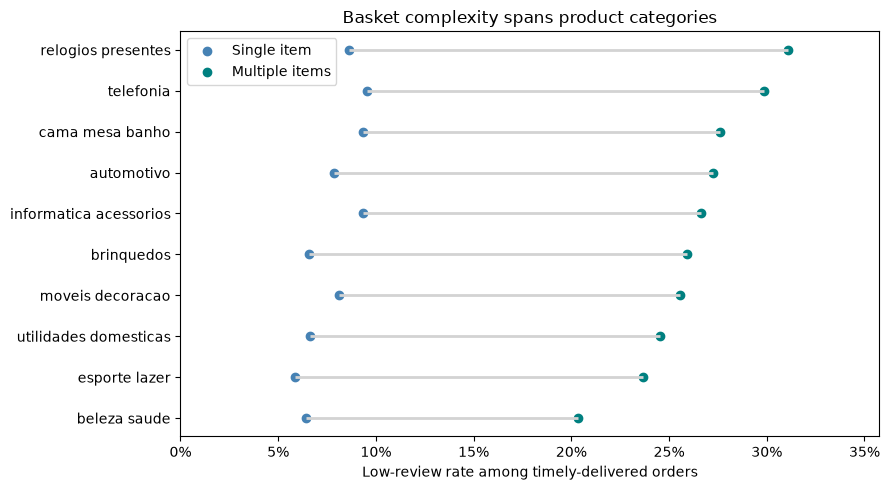

In [124]:
# Compare basket types within the ten most common categories.
category_plot = category_comparison.loc["Timely delivered"].reindex(
    category_rates.head(10).index
).dropna()
category_plot = category_plot.sort_values("Multiple items")
category_labels = category_plot.index.str.replace("_", " ")
y_positions = np.arange(len(category_plot))

fig, ax = plt.subplots(figsize=(9, 5))
ax.hlines(
    y_positions,
    category_plot["Single item"],
    category_plot["Multiple items"],
    color="lightgray",
    linewidth=2,
)
for column, color in [("Single item", "steelblue"), ("Multiple items", "teal")]:
    ax.scatter(category_plot[column], y_positions, label=column, color=color)
ax.set_yticks(y_positions, labels=category_labels)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
ax.set(
    xlabel="Low-review rate among timely-delivered orders",
    title="Basket complexity spans product categories",
    xlim=(0, category_plot[["Single item", "Multiple items"]].max().max() * 1.15),
)
ax.legend()
plt.tight_layout()
plt.show()

#### Product Frequency Versus Low-review Rate

The same ten listings are shown in both panels. Counts identify listings frequently present in low-reviewed orders; rates account for their reviewed-order exposure. Labels use category and shortened product ID because product names are unavailable. The annotations show reviewed-order counts. The overall prevalence line is contextual, not an adjusted product benchmark; an order rating cannot identify a responsible item.

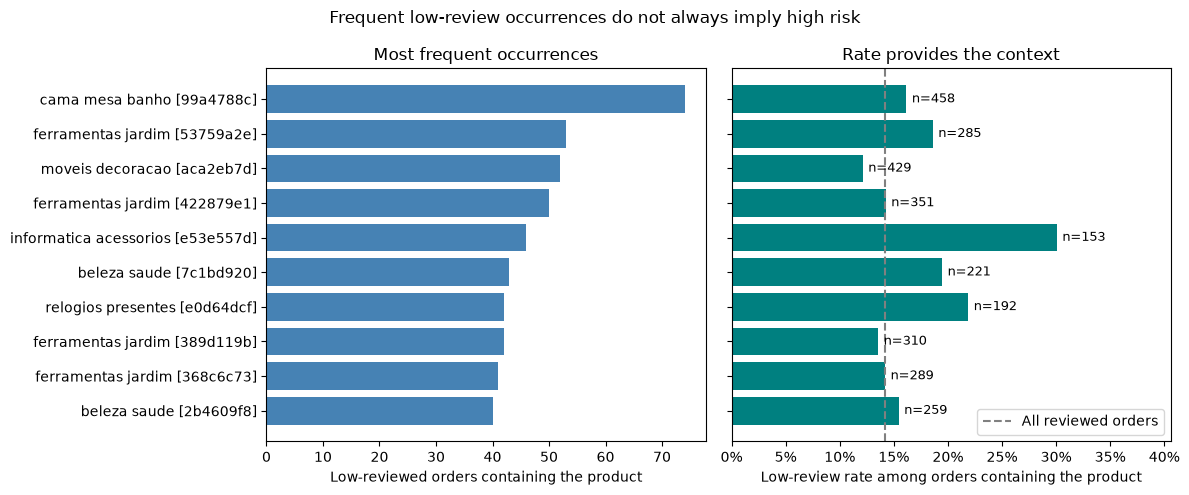

In [125]:
# Distinguish frequent low-review occurrences from elevated review rates.
product_plot = top_low_review_products.sort_values("low_reviews")
product_labels = [
    f"{row.category.replace('_', ' ')} [{product_id[:8]}]"
    for product_id, row in product_plot.iterrows()
]
y_positions = np.arange(len(product_plot))

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
axes[0].barh(y_positions, product_plot["low_reviews"], color="steelblue")
axes[0].set_yticks(y_positions, labels=product_labels)
axes[0].set_xlabel("Low-reviewed orders containing the product")
axes[0].set_title("Most frequent occurrences")

bars = axes[1].barh(y_positions, product_plot["low_review_rate"], color="teal")
axes[1].bar_label(
    bars,
    labels=[f"n={count}" for count in product_plot["reviewed_orders"]],
    padding=4,
    fontsize=9,
)
axes[1].axvline(
    basket_orders["low_review"].mean(),
    color="gray",
    linestyle="--",
    label="All reviewed orders",
)
axes[1].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
axes[1].set_xlim(0, product_plot["low_review_rate"].max() * 1.35)
axes[1].set_xlabel("Low-review rate among orders containing the product")
axes[1].set_title("Rate provides the context")
axes[1].legend(loc="lower right")
fig.suptitle("Frequent low-review occurrences do not always imply high risk")
plt.tight_layout()
plt.show()

#### Findings and Operational Implications

**Two distinct findings emerge: basket-complexity risk spans broad product categories, while frequent appearance in low-reviewed orders does not necessarily indicate a high-risk product.**

Among single-seller orders, low-review rates increase from 12.7% for one item to 23.5%, 26.6%, and 32.1% for two, three, and four or more items. Among timely single-seller orders, the corresponding rates are 7.6%, 19.7%, 23.3%, and 28.0%. Multiple-seller orders show still higher rates at the same item-count bands, but those groups are much smaller (114–949 reviewed orders overall).

Multi-item orders have higher low-review rates in all 21 categories meeting the minimum of 100 reviewed orders in each basket group, both overall and among timely deliveries. The pattern therefore is not confined to one broad category or eventual late delivery. These comparisons remain unadjusted for purchase period, individual products, seller mix, value, and other characteristics; mixed-category baskets also overlap across category groups.

Frequently occurring products in low-reviewed orders are not uniformly high-risk. For example, a furniture/decor listing appears in 52 low-reviewed orders out of 429 reviewed orders (12.1%, below the 14.2% overall rate), whereas a computer-accessories listing appears in 46 out of 153 (30.1%). Raw counts mix popularity with risk. Product IDs do not identify readable item names, and an order rating cannot attribute dissatisfaction to a particular item.

The findings support investigating multi-item and multi-seller order processes alongside product-specific issues. Operational records on completeness, damage, split shipments, communication, and support contacts could help distinguish possible explanations. The analysis does not establish that basket complexity itself causes dissatisfaction or that reducing basket size would improve outcomes.

The product summary does not test the same listing in single-item versus multi-item baskets, so it cannot establish whether individual-product composition explains the complexity pattern. The supported recommendation is to investigate both complex-order processes and listings with elevated low-review rates, rather than assign dissatisfaction exclusively to products or basket complexity.

## Part II — Seller-level event prioritization
The following section uses seller history at scoring dates to prioritize review and support. Its data and model objects are constructed separately from the order section. Shared variable names are reused only after the order analysis is complete; rerunning an earlier cell in isolation requires restoring that section's preceding setup.

### Seller-model objective

Historical seller information is used to identify sellers likely to generate at least one observed 1–2-star review among the next month's orders. Scores support allocating seller-management review and support; they do not establish seller fault or an underlying dissatisfaction rate.

The design uses historical eligibility, non-overlapping future order windows, review-maturation deadlines, and chronological train/validation/test periods. Reviews are selected at order grain before attribution to each participating seller.

In [126]:
# 1. Imports and reproducibility



warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 120)
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')
RANDOM_STATE = 42

### Seller source-data preparation

The seller section reconstructs its source tables and timestamps using the shared setup. Both sections use the repository's shared Olist source files. The raw-table audits and general exploration are documented in preprocessing and EDA rather than repeated here.

In [127]:
required_files = {
    'customers': 'olist_customers_dataset.csv',
    'geolocation': 'olist_geolocation_dataset.csv',
    'order_items': 'olist_order_items_dataset.csv',
    'payments': 'olist_order_payments_dataset.csv',
    'reviews': 'olist_order_reviews_dataset.csv',
    'orders': 'olist_orders_dataset.csv',
    'products': 'olist_products_dataset.csv',
    'sellers': 'olist_sellers_dataset.csv',
    'category_translation': 'product_category_name_translation.csv',
}

# Source CSV paths follow the repository directory structure.
data = {name: pd.read_csv(resolve_data_file(fname, 'raw')) for name, fname in required_files.items()}
for name, df in data.items():
    print(f'{name:22s}: {df.shape[0]:,} rows x {df.shape[1]} columns')

customers             : 99,441 rows x 5 columns
geolocation           : 1,000,163 rows x 5 columns
order_items           : 112,650 rows x 7 columns
payments              : 103,886 rows x 5 columns
reviews               : 99,224 rows x 7 columns
orders                : 99,441 rows x 8 columns
products              : 32,951 rows x 9 columns
sellers               : 3,095 rows x 4 columns
category_translation  : 71 rows x 2 columns


In [128]:
customers = data['customers'].copy()
geolocation = data['geolocation'].copy()
order_items = data['order_items'].copy()
payments = data['payments'].copy()
reviews = data['reviews'].copy()
orders = data['orders'].copy()
products = data['products'].copy()
sellers = data['sellers'].copy()
category_translation = data['category_translation'].copy()

for col in [
    'order_purchase_timestamp','order_approved_at','order_delivered_carrier_date',
    'order_delivered_customer_date','order_estimated_delivery_date'
]:
    orders[col] = pd.to_datetime(orders[col], errors='coerce')

reviews['review_creation_date'] = pd.to_datetime(reviews['review_creation_date'], errors='coerce')
reviews['review_answer_timestamp'] = pd.to_datetime(reviews['review_answer_timestamp'], errors='coerce')
reviews['review_time'] = reviews['review_answer_timestamp'].fillna(reviews['review_creation_date'])
order_items['shipping_limit_date'] = pd.to_datetime(order_items['shipping_limit_date'], errors='coerce')

# 6. Build one seller-order table
Each row below represents one seller within one order. This avoids duplicating seller totals while retaining product, freight, delivery, and shipping-deadline information.

In [129]:
items_enriched = order_items.merge(
    products[['product_id','product_category_name']], on='product_id', how='left'
)
seller_order = (
    items_enriched.groupby(['order_id','seller_id'], as_index=False)
    .agg(
        item_lines=('order_item_id','count'), sales=('price','sum'), freight=('freight_value','sum'),
        unique_products=('product_id','nunique'), unique_categories=('product_category_name','nunique'),
        last_shipping_limit=('shipping_limit_date','max')
    )
    .merge(orders[[
        'order_id','order_purchase_timestamp','order_delivered_carrier_date',
        'order_delivered_customer_date','order_estimated_delivery_date','order_status'
    ]], on='order_id', how='left')
)
seller_first_purchase = seller_order.groupby('seller_id').order_purchase_timestamp.min()
seller_order.head()

,order_id,seller_id,item_lines,sales,freight,unique_products,unique_categories,last_shipping_limit,order_purchase_timestamp,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,order_status
0,00010242fe8c5a6d1ba2dd792cb16214,48436dade18ac8b2bce089ec2a041202,1,58.900,13.290,1,1,2017-09-19 09:45:35,2017-09-13 08:59:02,2017-09-19 18:34:16,2017-09-20 23:43:48,2017-09-29,delivered
1,00018f77f2f0320c557190d7a144bdd3,dd7ddc04e1b6c2c614352b383efe2d36,1,239.900,19.930,1,1,2017-05-03 11:05:13,2017-04-26 10:53:06,2017-05-04 14:35:00,2017-05-12 16:04:24,2017-05-15,delivered
2,000229ec398224ef6ca0657da4fc703e,5b51032eddd242adc84c38acab88f23d,1,199.000,17.870,1,1,2018-01-18 14:48:30,2018-01-14 14:33:31,2018-01-16 12:36:48,2018-01-22 13:19:16,2018-02-05,delivered
3,00024acbcdf0a6daa1e931b038114c75,9d7a1d34a5052409006425275ba1c2b4,1,12.990,12.790,1,1,2018-08-15 10:10:18,2018-08-08 10:00:35,2018-08-10 13:28:00,2018-08-14 13:32:39,2018-08-20,delivered
4,00042b26cf59d7ce69dfabb4e55b4fd9,df560393f3a51e74553ab94004ba5c87,1,199.900,18.140,1,1,2017-02-13 13:57:51,2017-02-04 13:57:51,2017-02-16 09:46:09,2017-03-01 16:42:31,2017-03-17,delivered


# 7. Leakage-safe seller snapshots with label maturation

**Unit:** one historically eligible seller at one scoring date.  
**Eligibility:** at least 5 orders in the prior 180 days, using historical information only.  
**Outcome window:** the next calendar month.  
**Maturation window:** one additional month for reviews to arrive before the next scoring date.  
**Target:** 1 if the seller generates at least one observed 1–2 star review in the next-month order cohort; otherwise 0.

Scoring dates are two months apart. Therefore future order windows do not overlap, and each snapshot’s labels are fully defined by the next scoring date.

### Historical delivery timing definition
Historical lateness uses calendar dates, consistent with the order-level analysis and final EDA. An order is counted as historically late only when its actual delivery calendar date is after its estimated delivery calendar date. The delivery must have been observed before the scoring cutoff, and both delivery and estimated dates must be available; otherwise this feature remains missing for that seller-order.

In [130]:
def build_seller_cx_snapshot(cutoff, review_strategy='latest', history_days=180, min_history_orders=5):
    cutoff = pd.Timestamp(cutoff)
    outcome_end = cutoff + pd.offsets.MonthBegin(1)      # next-month order window ends
    label_deadline = cutoff + pd.DateOffset(months=2)    # reviews must be observable by next score date
    history_start = cutoff - pd.Timedelta(days=history_days)

    hist = seller_order[(seller_order.order_purchase_timestamp>=history_start) & (seller_order.order_purchase_timestamp<cutoff)].copy()
    hist['known_delivery'] = hist.order_delivered_customer_date.notna() & (hist.order_delivered_customer_date<cutoff)
    hist['late_known'] = np.where(
        hist.known_delivery & hist.order_estimated_delivery_date.notna(),
        hist.order_delivered_customer_date.dt.normalize()
        > hist.order_estimated_delivery_date.dt.normalize(),
        np.nan
    )
    hist['delivery_days_known'] = np.where(
        hist.known_delivery,
        (hist.order_delivered_customer_date-hist.order_purchase_timestamp).dt.total_seconds()/86400,
        np.nan
    )
    hist['known_handoff'] = hist.order_delivered_carrier_date.notna() & (hist.order_delivered_carrier_date<cutoff)
    hist['deadline_miss_known'] = np.where(
        hist.known_handoff & hist.last_shipping_limit.notna(),
        hist.order_delivered_carrier_date>hist.last_shipping_limit, np.nan
    )

    hist_agg = hist.groupby('seller_id', as_index=False).agg(
        hist_orders=('order_id','nunique'), hist_sales=('sales','sum'), hist_freight=('freight','sum'),
        hist_item_lines=('item_lines','sum'), hist_unique_products=('unique_products','sum'),
        hist_unique_categories=('unique_categories','sum'), hist_late_rate=('late_known','mean'),
        hist_avg_delivery_days=('delivery_days_known','mean'), hist_deadline_miss_rate=('deadline_miss_known','mean'),
        last_order_time=('order_purchase_timestamp','max')
    )
    hist_agg['hist_avg_order_value'] = hist_agg.hist_sales/hist_agg.hist_orders
    hist_agg['hist_freight_ratio'] = hist_agg.hist_freight/(hist_agg.hist_sales+hist_agg.hist_freight).replace(0,np.nan)
    hist_agg['hist_items_per_order'] = hist_agg.hist_item_lines/hist_agg.hist_orders
    hist_agg['hist_products_per_order'] = hist_agg.hist_unique_products/hist_agg.hist_orders
    hist_agg['hist_categories_per_order'] = hist_agg.hist_unique_categories/hist_agg.hist_orders
    hist_agg['seller_recency_days'] = (cutoff-hist_agg.last_order_time).dt.total_seconds()/86400
    hist_agg['seller_tenure_days'] = hist_agg.seller_id.map(seller_first_purchase)
    hist_agg['seller_tenure_days'] = (cutoff-hist_agg.seller_tenure_days).dt.total_seconds()/86400

    # Resolve review outcome at ORDER grain before attributing it to each seller.
    # This preserves every seller on multi-seller orders, without counting repeated
    # review records as separate orders.
    hist_orders = hist[['order_id', 'seller_id']].drop_duplicates()
    eligible_hist_reviews = reviews.loc[reviews.review_time < cutoff].copy()
    if review_strategy == 'latest':
        order_hist_review = (eligible_hist_reviews.sort_values(['order_id', 'review_time'])
                             .drop_duplicates('order_id', keep='last')[['order_id', 'review_score']])
    elif review_strategy == 'first':
        order_hist_review = (eligible_hist_reviews.sort_values(['order_id', 'review_time'])
                             .drop_duplicates('order_id', keep='first')[['order_id', 'review_score']])
    elif review_strategy == 'mean':
        order_hist_review = eligible_hist_reviews.groupby('order_id', as_index=False)['review_score'].mean()
    else:
        raise ValueError('review_strategy must be latest, first, or mean')
    hist_review_order = hist_orders.merge(order_hist_review, on='order_id', how='inner')

    if len(hist_review_order):
        hist_review_order['hist_low_review']=(hist_review_order.review_score<=2).astype(int)
        hist_review_agg=hist_review_order.groupby('seller_id',as_index=False).agg(
            hist_avg_review=('review_score','mean'), hist_low_review_rate=('hist_low_review','mean'), hist_reviewed_orders=('order_id','nunique')
        )
    else:
        hist_review_agg=pd.DataFrame(columns=['seller_id','hist_avg_review','hist_low_review_rate','hist_reviewed_orders'])
    hist_agg=hist_agg.merge(hist_review_agg,on='seller_id',how='left')

    snapshot=hist_agg[hist_agg.hist_orders>=min_history_orders].copy()  # historical-only eligibility

    future_orders = seller_order[
        (seller_order.order_purchase_timestamp>=cutoff) & (seller_order.order_purchase_timestamp<outcome_end)
    ][['order_id','seller_id']].drop_duplicates()
    # Review records are selected once per order, then associated with ALL sellers
    # on that order. This is order-level attribution, not proof of seller causation.
    eligible_future_reviews = reviews.loc[reviews.review_time < label_deadline].copy()
    if review_strategy == 'latest':
        order_future_review = (eligible_future_reviews.sort_values(['order_id', 'review_time'])
                               .drop_duplicates('order_id', keep='last')[['order_id', 'review_score']])
    elif review_strategy == 'first':
        order_future_review = (eligible_future_reviews.sort_values(['order_id', 'review_time'])
                               .drop_duplicates('order_id', keep='first')[['order_id', 'review_score']])
    elif review_strategy == 'mean':
        order_future_review = eligible_future_reviews.groupby('order_id', as_index=False)['review_score'].mean()
    else:
        raise ValueError('review_strategy must be latest, first, or mean')
    future_review_order = future_orders.merge(order_future_review, on='order_id', how='inner')

    if len(future_review_order):
        future_review_order['future_low_review']=(future_review_order.review_score<=2).astype(int)
        future_outcome=future_review_order.groupby('seller_id',as_index=False).agg(
            future_reviewed_orders=('order_id','nunique'), future_low_review_events=('future_low_review','sum'), future_avg_review=('review_score','mean')
        )
    else:
        future_outcome=pd.DataFrame(columns=['seller_id','future_reviewed_orders','future_low_review_events','future_avg_review'])

    snapshot=snapshot.merge(future_outcome,on='seller_id',how='left')
    snapshot['future_reviewed_orders']=snapshot.future_reviewed_orders.fillna(0)
    snapshot['future_low_review_events']=snapshot.future_low_review_events.fillna(0)
    snapshot['target']=(snapshot.future_low_review_events>=1).astype(int)
    snapshot['cutoff']=cutoff
    snapshot['outcome_end']=outcome_end
    snapshot['label_deadline']=label_deadline
    snapshot['review_strategy']=review_strategy
    return snapshot

# 8. Build non-overlapping scoring snapshots
The six scoring dates are two months apart. Train, validation, and test periods are chronological.

,seller_snapshots,positive_rate,avg_future_reviewed_orders
cutoff,,,
2017-07-01,472,0.324,7.133
2017-09-01,580,0.291,6.202
2017-11-01,650,0.443,9.349
2018-01-01,791,0.382,7.630
2018-03-01,921,0.457,6.988
2018-05-01,1030,0.275,5.834


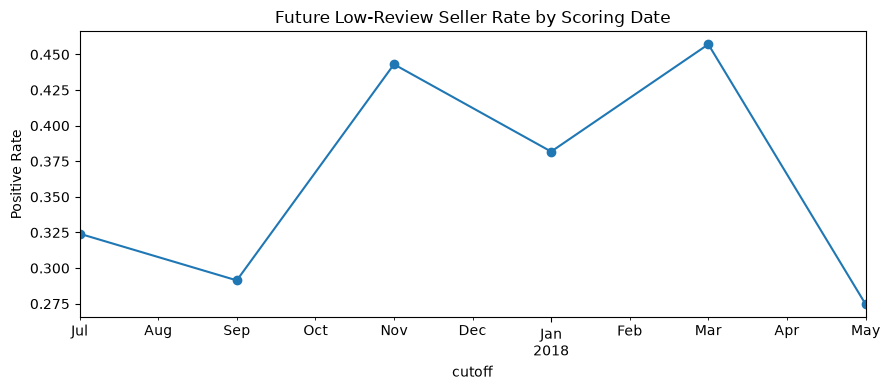

In [131]:
snapshot_dates = pd.to_datetime([
    '2017-07-01','2017-09-01','2017-11-01',
    '2018-01-01','2018-03-01','2018-05-01'
])
model_data = pd.concat([build_seller_cx_snapshot(d,'latest') for d in snapshot_dates], ignore_index=True)
snapshot_summary = model_data.groupby('cutoff').agg(
    seller_snapshots=('seller_id','size'), positive_rate=('target','mean'),
    avg_future_reviewed_orders=('future_reviewed_orders','mean')
)
display(snapshot_summary)
plt.figure(figsize=(9,4)); snapshot_summary.positive_rate.plot(marker='o');
plt.title('Future Low-Review Seller Rate by Scoring Date'); plt.ylabel('Positive Rate'); plt.tight_layout(); plt.show()

# 9. Predictor set
All predictors are historical and available before the scoring date.

### Interpretation of historical product and category features
`hist_unique_products` and `hist_unique_categories` **sum the distinct counts calculated within each historical seller-order**. They are not the number of distinct product IDs or categories across the entire 180-day history. The per-order average features divide these sums by historical order count. The feature calculations remain unchanged.

In [132]:
features = [
    'hist_orders','hist_sales','hist_freight','hist_item_lines','hist_unique_products','hist_unique_categories',
    'hist_late_rate','hist_avg_delivery_days','hist_deadline_miss_rate','hist_avg_order_value','hist_freight_ratio',
    'hist_items_per_order','hist_products_per_order','hist_categories_per_order','seller_recency_days','seller_tenure_days',
    'hist_avg_review','hist_low_review_rate','hist_reviewed_orders'
]
feature_dictionary = pd.DataFrame([
    ['hist_orders','Historical order count'],['hist_sales','Historical merchandise sales'],
    ['hist_freight','Historical freight value'],['hist_item_lines','Historical item-line volume'],
    ['hist_unique_products','Sum of per-order distinct product counts in history'],['hist_unique_categories','Sum of per-order distinct category counts in history'],
    ['hist_late_rate','Known historical late-delivery rate'],['hist_avg_delivery_days','Average known historical delivery time'],
    ['hist_deadline_miss_rate','Known seller shipping-deadline miss rate'],['hist_avg_order_value','Historical average order value'],
    ['hist_freight_ratio','Freight share of merchandise + freight'],['hist_items_per_order','Historical item lines per order'],
    ['hist_products_per_order','Historical products per order'],['hist_categories_per_order','Historical categories per order'],
    ['seller_recency_days','Days since most recent order'],['seller_tenure_days','Days since first observed seller order'],
    ['hist_avg_review','Average historical review known by cutoff'],['hist_low_review_rate','Historical 1–2 star review rate'],
    ['hist_reviewed_orders','Historical reviewed-order count']
], columns=['feature','business_meaning'])
feature_dictionary

,feature,business_meaning
0,hist_orders,Historical order count
1,hist_sales,Historical merchandise sales
2,hist_freight,Historical freight value
3,hist_item_lines,Historical item-line volume
4,hist_unique_products,Sum of per-order distinct product counts in hi...
5,hist_unique_categories,Sum of per-order distinct category counts in h...
6,hist_late_rate,Known historical late-delivery rate
7,hist_avg_delivery_days,Average known historical delivery time
8,hist_deadline_miss_rate,Known seller shipping-deadline miss rate
9,hist_avg_order_value,Historical average order value


# 11. Chronological train / validation / test design
- **Train:** July, September, November 2017 snapshots  
- **Validation:** January and March 2018 snapshots  
- **Test:** May 2018 snapshot

The May test snapshot is untouched during model selection and tuning.

In [133]:
train=model_data[model_data.cutoff.isin(pd.to_datetime(['2017-07-01','2017-09-01','2017-11-01']))].copy()
validation=model_data[model_data.cutoff.isin(pd.to_datetime(['2018-01-01','2018-03-01']))].copy()
test=model_data[model_data.cutoff.eq(pd.Timestamp('2018-05-01'))].copy()
split_summary=pd.DataFrame({
    'split':['Train','Validation','Test'],'rows':[len(train),len(validation),len(test)],
    'positive_rate':[train.target.mean(),validation.target.mean(),test.target.mean()],
    'first_cutoff':[train.cutoff.min(),validation.cutoff.min(),test.cutoff.min()],
    'last_cutoff':[train.cutoff.max(),validation.cutoff.max(),test.cutoff.max()]
})
split_summary

,split,rows,positive_rate,first_cutoff,last_cutoff
0,Train,1702,0.358,2017-07-01,2017-11-01
1,Validation,1712,0.422,2018-01-01,2018-03-01
2,Test,1030,0.275,2018-05-01,2018-05-01


# 12. Baseline and candidate models
A majority-class baseline can look accurate while identifying no positive sellers. The business use is ranking, so PR-AUC, ROC-AUC, lift, and capture are central.

In [134]:
baseline_accuracy=max(validation.target.mean(),1-validation.target.mean())
display(pd.DataFrame({'baseline':['Predict majority class'],'validation_accuracy':[baseline_accuracy],'positive_recall':[0.0]}))

target='target'
scaled=Pipeline([('imputer',SimpleImputer(strategy='median')),('scaler',StandardScaler())])
treeprep=Pipeline([('imputer',SimpleImputer(strategy='median'))])
models={
    'Logistic Regression':Pipeline([('prep',scaled),('model',LogisticRegression(max_iter=1000,class_weight='balanced',random_state=RANDOM_STATE))]),
    'Decision Tree':Pipeline([('prep',treeprep),('model',DecisionTreeClassifier(max_depth=6,min_samples_leaf=20,class_weight='balanced',random_state=RANDOM_STATE))]),
    'Random Forest':Pipeline([('prep',treeprep),('model',RandomForestClassifier(n_estimators=120,max_depth=10,min_samples_leaf=8,class_weight='balanced_subsample',random_state=RANDOM_STATE,n_jobs=-1))])
}

,baseline,validation_accuracy,positive_recall
0,Predict majority class,0.578,0.000


In [135]:
def top_fraction_metrics(y_true, probability, fraction=.10):
    frame=pd.DataFrame({'actual':np.asarray(y_true),'probability':np.asarray(probability)}).sort_values('probability',ascending=False)
    n=max(1,int(np.ceil(len(frame)*fraction))); selected=frame.head(n); base=frame.actual.mean()
    precision_sel=selected.actual.mean(); capture=selected.actual.sum()/frame.actual.sum() if frame.actual.sum()>0 else np.nan
    lift=precision_sel/base if base>0 else np.nan
    return precision_sel,capture,lift

def metric_row(name,y_true,probability,seconds=np.nan,threshold=.50):
    pred=(np.asarray(probability)>=threshold).astype(int); p10,c10,l10=top_fraction_metrics(y_true,probability,.10)
    return {'model':name,'seconds':seconds,'accuracy':accuracy_score(y_true,pred),'precision':precision_score(y_true,pred,zero_division=0),
            'recall':recall_score(y_true,pred,zero_division=0),'f1':f1_score(y_true,pred,zero_division=0),
            'roc_auc':roc_auc_score(y_true,probability),'pr_auc':average_precision_score(y_true,probability),
            'top10_precision':p10,'top10_capture':c10,'top10_lift':l10}

validation_probabilities={}; fitted_models={}; rows=[]
for name,model in models.items():
    print('Training',name,'...'); t0=perf_counter(); model.fit(train[features],train[target]); prob=model.predict_proba(validation[features])[:,1]; elapsed=perf_counter()-t0
    fitted_models[name]=model; validation_probabilities[name]=prob; rows.append(metric_row(name,validation[target],prob,elapsed)); print(f'Finished in {elapsed:.2f}s')
validation_results=pd.DataFrame(rows).sort_values(['top10_lift','pr_auc'],ascending=False).reset_index(drop=True)
validation_results

Training Logistic Regression ...
Finished in 0.01s
Training Decision Tree ...
Finished in 0.02s
Training Random Forest ...
Finished in 0.18s


,model,seconds,accuracy,precision,recall,f1,roc_auc,pr_auc,top10_precision,top10_capture,top10_lift
0,Random Forest,0.176,0.709,0.692,0.557,0.618,0.757,0.715,0.866,0.206,2.051
1,Logistic Regression,0.011,0.695,0.653,0.595,0.622,0.754,0.707,0.849,0.202,2.010
2,Decision Tree,0.019,0.691,0.667,0.537,0.595,0.730,0.667,0.837,0.199,1.982


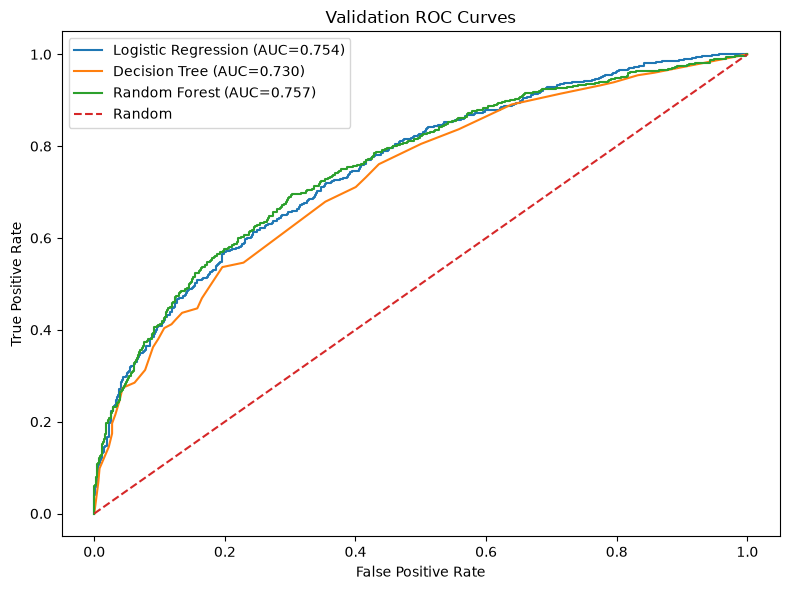

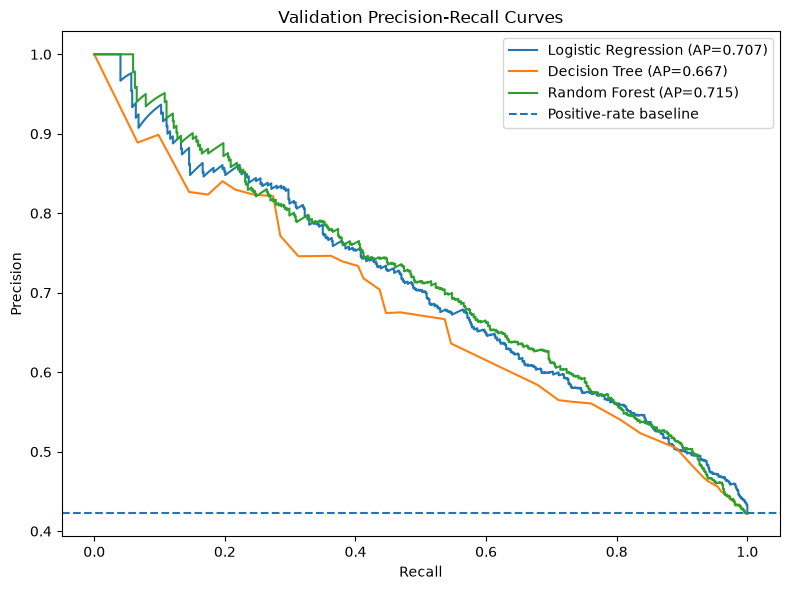

In [136]:
plt.figure(figsize=(8,6))
for name,prob in validation_probabilities.items():
    fpr,tpr,_=roc_curve(validation[target],prob); plt.plot(fpr,tpr,label=f'{name} (AUC={roc_auc_score(validation[target],prob):.3f})')
plt.plot([0,1],[0,1],linestyle='--',label='Random'); plt.title('Validation ROC Curves'); plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate'); plt.legend(); plt.tight_layout(); plt.show()

plt.figure(figsize=(8,6))
for name,prob in validation_probabilities.items():
    precision_curve,recall_curve,_=precision_recall_curve(validation[target],prob); plt.plot(recall_curve,precision_curve,label=f'{name} (AP={average_precision_score(validation[target],prob):.3f})')
plt.axhline(validation[target].mean(),linestyle='--',label='Positive-rate baseline'); plt.title('Validation Precision-Recall Curves'); plt.xlabel('Recall'); plt.ylabel('Precision'); plt.legend(); plt.tight_layout(); plt.show()

# 13. Capacity analysis and tuning
The seller-success team may only have capacity to review a fraction of sellers. The analysis evaluates top 10%, 20%, and 30% ranking scenarios and uses top-decile lift as the primary selection metric because seller-success capacity is limited; PR-AUC is the secondary ranking metric. Random Forest is tuned only if it leads under this rule.

In [137]:
def capacity_metrics(y_true,probability,fractions=(.10,.20,.30)):
    frame=pd.DataFrame({'actual':np.asarray(y_true),'probability':np.asarray(probability)}).sort_values('probability',ascending=False)
    total=frame.actual.sum(); base=frame.actual.mean(); rows=[]
    for frac in fractions:
        n=max(1,int(np.ceil(len(frame)*frac))); sel=frame.head(n); precision_sel=sel.actual.mean(); capture=sel.actual.sum()/total if total>0 else np.nan; lift=precision_sel/base if base>0 else np.nan
        rows.append({'capacity':f'Top {int(frac*100)}%','selected_sellers':n,'precision_selected':precision_sel,'capture_of_all_positives':capture,'lift':lift})
    return pd.DataFrame(rows)

caps=[]
for name,prob in validation_probabilities.items():
    t=capacity_metrics(validation[target],prob); t.insert(0,'model',name); caps.append(t)
validation_capacity=pd.concat(caps,ignore_index=True); display(validation_capacity)

leading_model_name=validation_results.iloc[0].model; print('Leading validation model:',leading_model_name)
if leading_model_name=='Random Forest':
    candidates=[
        {'n_estimators':100,'max_depth':8,'min_samples_leaf':10,'max_features':'sqrt'},
        {'n_estimators':150,'max_depth':12,'min_samples_leaf':8,'max_features':'sqrt'},
        {'n_estimators':200,'max_depth':16,'min_samples_leaf':6,'max_features':'sqrt'}]
    tuning_rows=[]; tuned=[]
    for i,p in enumerate(candidates,1):
        m=Pipeline([('prep',SimpleImputer(strategy='median')),('model',RandomForestClassifier(**p,class_weight='balanced_subsample',random_state=RANDOM_STATE,n_jobs=-1))])
        m.fit(train[features],train[target]); prob=m.predict_proba(validation[features])[:,1]; row=metric_row(f'RF Candidate {i}',validation[target],prob); row.update(p); tuning_rows.append(row); tuned.append(m)
    rf_tuning_results=pd.DataFrame(tuning_rows).sort_values(['top10_lift','pr_auc'],ascending=False).reset_index(); display(rf_tuning_results)
    best_model=tuned[int(rf_tuning_results.loc[0,'index'])]
else:
    best_model=fitted_models[leading_model_name]
best_validation_probability=best_model.predict_proba(validation[features])[:,1]
print('Selected validation ROC-AUC:',round(roc_auc_score(validation[target],best_validation_probability),3))
print('Selected validation PR-AUC:',round(average_precision_score(validation[target],best_validation_probability),3))

,model,capacity,selected_sellers,precision_selected,capture_of_all_positives,lift
0,Logistic Regression,Top 10%,172,0.849,0.202,2.010
1,Logistic Regression,Top 20%,343,0.767,0.364,1.816
2,Logistic Regression,Top 30%,514,0.702,0.499,1.663
3,Decision Tree,Top 10%,172,0.837,0.199,1.982
4,Decision Tree,Top 20%,343,0.752,0.357,1.781
5,Decision Tree,Top 30%,514,0.669,0.476,1.585
6,Random Forest,Top 10%,172,0.866,0.206,2.051
7,Random Forest,Top 20%,343,0.778,0.369,1.843
8,Random Forest,Top 30%,514,0.712,0.506,1.686


Leading validation model: Random Forest


,index,model,seconds,accuracy,precision,recall,f1,roc_auc,pr_auc,top10_precision,top10_capture,top10_lift,n_estimators,max_depth,min_samples_leaf,max_features
0,0,RF Candidate 1,NaN,0.701,0.682,0.546,0.607,0.756,0.715,0.872,0.207,2.065,100,8,10,sqrt
1,2,RF Candidate 3,NaN,0.699,0.687,0.526,0.596,0.752,0.709,0.860,0.205,2.038,200,16,6,sqrt
2,1,RF Candidate 2,NaN,0.704,0.686,0.553,0.613,0.753,0.710,0.855,0.203,2.024,150,12,8,sqrt


Selected validation ROC-AUC: 0.756
Selected validation PR-AUC: 0.715


### Seller target and business interpretation
The target is whether a historically eligible seller has **at least one observed 1–2-star reviewed order in the following month**, not the seller's underlying dissatisfaction rate. Sellers with no observed future low-review event, including those without reviewed future orders, receive a zero label; this is not evidence of satisfaction. Sellers with more future orders have more opportunities to trigger the event. For multi-seller orders, the same order-level review is associated with each participating seller without identifying responsibility. The model provides a candidate seller-support ranking, but incremental value over a simple historical-activity ranking has **not** been demonstrated and should be tested before recommending deployment.

# 14. Final fit and held-out test evaluation
After model selection using training and validation data only, the selected model is refitted on both sets and evaluated on the May 2018 test snapshot.

,model,seconds,accuracy,precision,recall,f1,roc_auc,pr_auc,top10_precision,top10_capture,top10_lift
0,Final Seller CX Risk Model,NaN,0.707,0.477,0.689,0.564,0.791,0.622,0.757,0.276,2.756


              precision    recall  f1-score   support

           0      0.858     0.714     0.779       747
           1      0.477     0.689     0.564       283

    accuracy                          0.707      1030
   macro avg      0.668     0.701     0.671      1030
weighted avg      0.753     0.707     0.720      1030



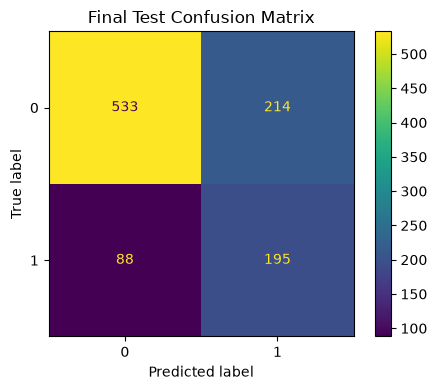

,capacity,selected_sellers,precision_selected,capture_of_all_positives,lift
0,Top 10%,103,0.757,0.276,2.756
1,Top 20%,206,0.597,0.435,2.173
2,Top 30%,309,0.528,0.576,1.920


In [138]:
train_validation=pd.concat([train,validation],ignore_index=True)
final_model=clone(best_model); final_model.fit(train_validation[features],train_validation[target])
test_probability=final_model.predict_proba(test[features])[:,1]
test_metrics=metric_row('Final Seller CX Risk Model',test[target],test_probability)
display(pd.DataFrame([test_metrics]))

test_prediction=(test_probability>=.50).astype(int)
print(classification_report(test[target],test_prediction,digits=3))
fig,ax=plt.subplots(figsize=(5,4)); ConfusionMatrixDisplay.from_predictions(test[target],test_prediction,ax=ax); plt.title('Final Test Confusion Matrix'); plt.tight_layout(); plt.show()

test_capacity=capacity_metrics(test[target],test_probability); display(test_capacity)

# 15. Feature importance
Feature importance describes what the Random Forest uses for ranking; it does not prove causality.

,feature,importance
0,seller_recency_days,0.151
1,hist_item_lines,0.101
2,hist_orders,0.096
3,hist_unique_products,0.094
4,hist_freight,0.089
5,hist_unique_categories,0.087
6,seller_tenure_days,0.066
7,hist_reviewed_orders,0.053
8,hist_sales,0.039
9,hist_avg_delivery_days,0.033


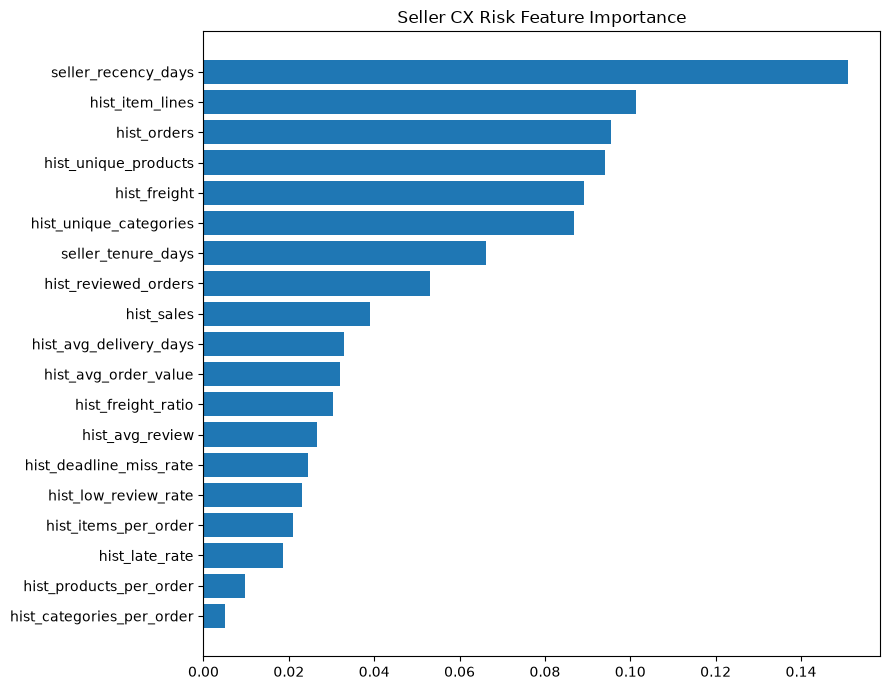

In [139]:
if hasattr(final_model.named_steps['model'],'feature_importances_'):
    importance=pd.DataFrame({'feature':features,'importance':final_model.named_steps['model'].feature_importances_}).sort_values('importance',ascending=False).reset_index(drop=True)
    display(importance)
    p=importance.sort_values('importance'); plt.figure(figsize=(9,7)); plt.barh(p.feature,p.importance); plt.title('Seller CX Risk Feature Importance'); plt.tight_layout(); plt.show()
else:
    print('Selected model does not expose tree feature importance.')

# 16. Review-definition sensitivity
Seller snapshots are reconstructed using latest, mean, and first review definitions to assess whether multiple reviews change the conclusion.

In [140]:
sensitivity=[]
for strategy in ['latest','mean','first']:
    sd=pd.concat([build_seller_cx_snapshot(d,strategy) for d in snapshot_dates],ignore_index=True)
    st=sd[sd.cutoff.isin(pd.to_datetime(['2017-07-01','2017-09-01','2017-11-01','2018-01-01','2018-03-01']))].copy()
    ss=sd[sd.cutoff.eq(pd.Timestamp('2018-05-01'))].copy()
    sm=clone(final_model); sm.fit(st[features],st[target]); sp=sm.predict_proba(ss[features])[:,1]; top20=capacity_metrics(ss[target],sp,(.20,)).iloc[0]
    sensitivity.append({'review_strategy':strategy,'test_rows':len(ss),'positive_rate':ss[target].mean(),'roc_auc':roc_auc_score(ss[target],sp),'pr_auc':average_precision_score(ss[target],sp),'top20_precision':top20.precision_selected,'top20_capture':top20.capture_of_all_positives,'top20_lift':top20.lift})
review_sensitivity=pd.DataFrame(sensitivity); review_sensitivity

,review_strategy,test_rows,positive_rate,roc_auc,pr_auc,top20_precision,top20_capture,top20_lift
0,latest,1030,0.275,0.791,0.622,0.597,0.435,2.173
1,mean,1030,0.275,0.790,0.618,0.592,0.431,2.155
2,first,1030,0.276,0.788,0.616,0.583,0.423,2.113


# 17. Technical Model Brief

### What was tried
Logistic Regression, Decision Tree, and Random Forest were compared on chronological validation data. Model selection prioritizes top-decile lift because the business action is capacity-constrained seller review; PR-AUC is used as a secondary ranking metric. Random Forest is tuned if it leads under this rule.

### Why
The models provide an interpretable linear benchmark, a simple nonlinear benchmark, and an ensemble capable of interactions.

### What the model supports
The seller model estimates the probability that a historically active seller will generate at least one observed 1–2 star review in the next-month order cohort.

### How it complements the order model
- **Order model:** early warning for individual orders at placement time.
- **Seller model:** next-month customer-experience risk for seller management.

### Decision use
Scores support ranking sellers for review and support under limited capacity; they do not justify automatic penalties or removal.

### Final model selection
Random Forest was selected because the business use case focuses on prioritizing sellers with limited review capacity. On validation data, the tuned model achieved a top-decile lift of 2.07×, PR-AUC of 0.715, and ROC-AUC of 0.756. These results supported its selection for the final evaluation.

On the May 2018 held-out test snapshot, the final Random Forest achieved ROC-AUC of 0.791 and PR-AUC of 0.622. At a top-20% seller-review capacity, the selected group captured 43.5% of sellers with an observed future low-review event, representing a 2.17× lift over random selection.



### Seller-model limitations and next steps

1. Historical public data may not represent current marketplace conditions.
2. Reviews are observational and not every order receives a review; no observed low review does not guarantee satisfaction.
3. Feature importance is predictive, not causal.
4. Sellers can appear in multiple snapshots, although future outcome windows are non-overlapping and labels mature before the next scoring date.
5. Eligibility is historical-only; future order volume is never used to decide who gets scored.
6. The dataset omits inventory availability, staffing, support history, and intervention history.
7. True intervention costs are unavailable, so dollar ROI should not be invented.
8. A prospective pilot and drift monitoring would be required before deployment.

### Recommended next steps
- Evaluation of incremental targeting value over a simple historical-activity ranking before operational deployment.
- Definition of a prospective seller-review capacity, such as top 20%, for a controlled pilot if incremental value is demonstrated.
- Prospective tracking of seller outreach, low-review incidence, and fulfillment outcomes.
- Evaluation of richer operational features when available.

8. **Multiple-seller order attribution:** A review belongs to the order. For multi-seller orders, the same order review is associated with each participating seller; it cannot identify which seller caused the outcome. Reviews are deduplicated at the order level before joining to sellers.
9. **Target exposure:** The target is at least one observed low-review event among the next month's orders, not a seller's underlying low-review rate. Higher-volume sellers have more opportunities for a positive event. Sellers without an observed low review (including sellers without reviewed future orders) receive a zero label; this is not proof of satisfaction.
10. **Review maturation:** The label deadline provides a consistent observation window, not a guarantee that all reviews have arrived.


Review-definition sensitivity reuses the May test cohort after the primary evaluation. This is a held-out historical evaluation with post-evaluation sensitivity checks, not an indefinitely untouched test. The one-month review-maturation gap defines an observed-by-deadline event and does not guarantee complete eventual review coverage.


# 19. Reproducibility and references

**GitHub repository:** https://github.com/asherdata1/supply-chain-decision-support

**Dataset citation (APA 7):**  
Olist. (2018). *Brazilian E-Commerce Public Dataset by Olist* [Data set]. Kaggle. https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce

The final team notebook should preserve visible GitHub commit history and document the Python environment/packages used for reproducibility.


## Project interpretation

The order model provides the project's primary evidence for customer-experience risk ranking at placement. Its timely-delivery diagnostic examines whether that signal extends beyond eventual lateness; it does not change operational eligibility.

The seller model supports a separate queue for historically active sellers likely to generate observed low-review events. Greater future activity creates more opportunities for such events. Business claims about seller quality, intervention benefit, or incremental value beyond activity require separate evidence.

Both analyses are retrospective and conditional on their respective review-observation rules. No combined order/seller scoring system or intervention effect is evaluated here. Any model deployment recommendation should be conditional on an activity-ranking benchmark and prospective evaluation.